In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [14]:
df = pd.read_csv("mlp_data.csv", header=None, index_col=0)
df.head()

,1,2,3,4,5,6,7,8,9,10,...,22,23,24,25,26,27,28,29,30,31
0,,,,,,,,,,,,,,,,,,,,,
842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [26]:
df.rename(columns={1: "target"}, inplace=True)
df.rename(columns={i:f"col_{i}" for i in range(2, 32)}, inplace=True)

In [27]:
df.shape

(569, 31)

In [28]:
df.dtypes

target     object
col_2     float64
col_3     float64
col_4     float64
col_5     float64
col_6     float64
col_7     float64
col_8     float64
col_9     float64
col_10    float64
col_11    float64
col_12    float64
col_13    float64
col_14    float64
col_15    float64
col_16    float64
col_17    float64
col_18    float64
col_19    float64
col_20    float64
col_21    float64
col_22    float64
col_23    float64
col_24    float64
col_25    float64
col_26    float64
col_27    float64
col_28    float64
col_29    float64
col_30    float64
col_31    float64
dtype: object

In [30]:
df["target"].unique()

array(['M', 'B'], dtype=object)

In [31]:
#Кол-во пропусков
int(df.isna().sum().sum())

0

In [33]:
df.describe()

,col_2,col_3,col_4,col_5,col_6,col_7,col_8,col_9,col_10,col_11,...,col_22,col_23,col_24,col_25,col_26,col_27,col_28,col_29,col_30,col_31
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [34]:
#Дубликатов нет
df.drop_duplicates().shape

(569, 31)

target
B    62.74
M    37.26
Name: proportion, dtype: float64


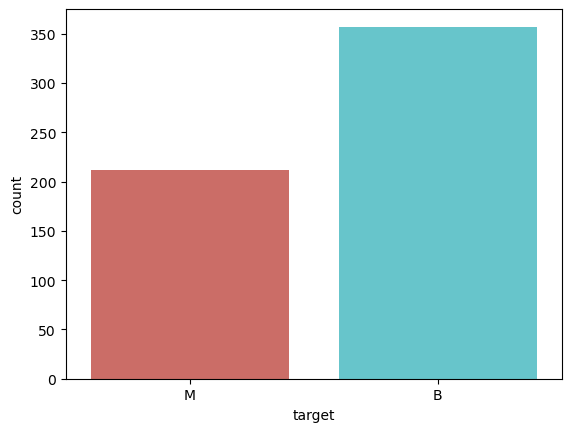

In [36]:
print(np.round(df["target"].value_counts(normalize=True) * 100, 2))
sns.countplot(data=df, x="target", palette="hls")
plt.show()

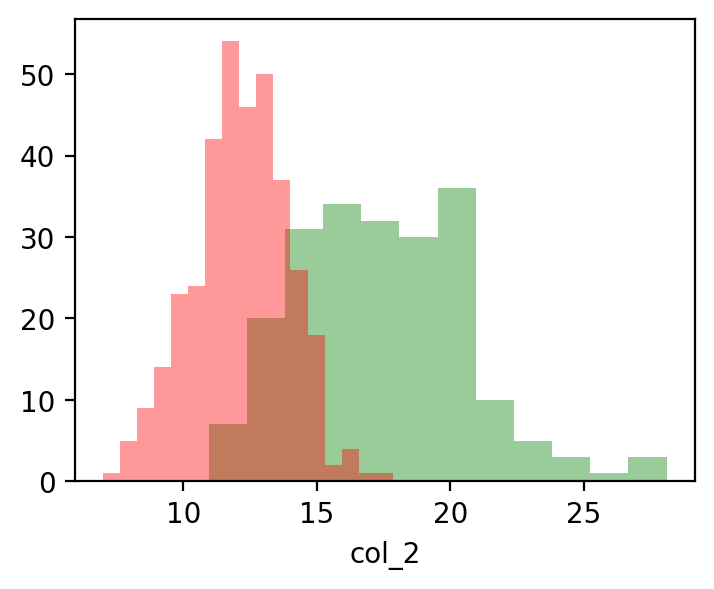

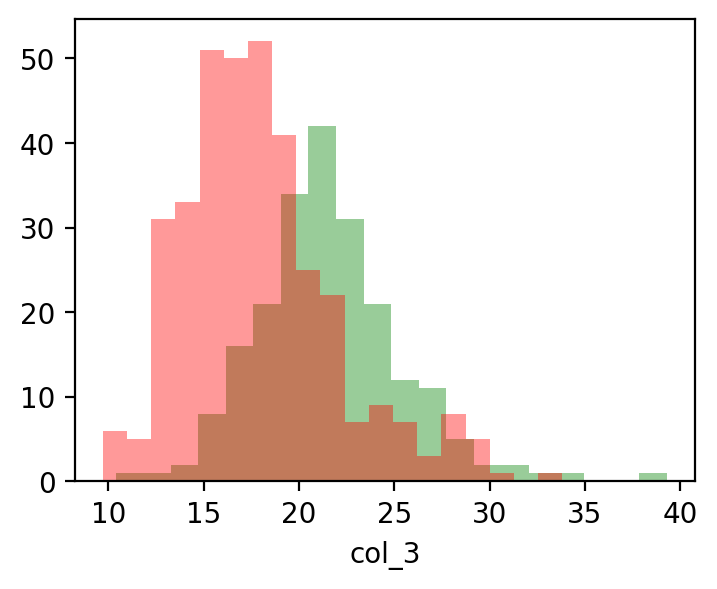

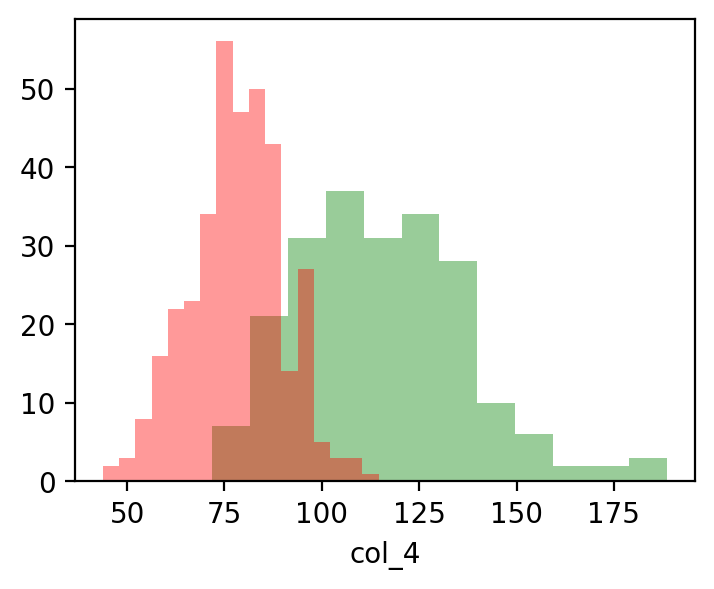

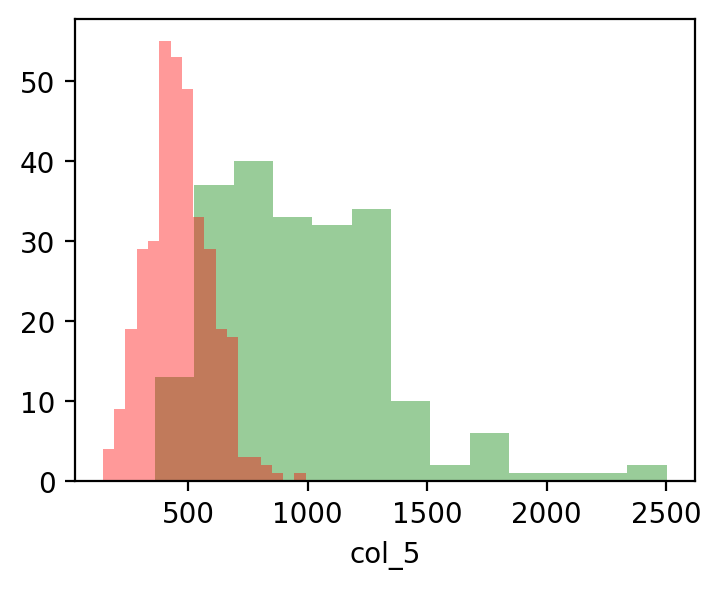

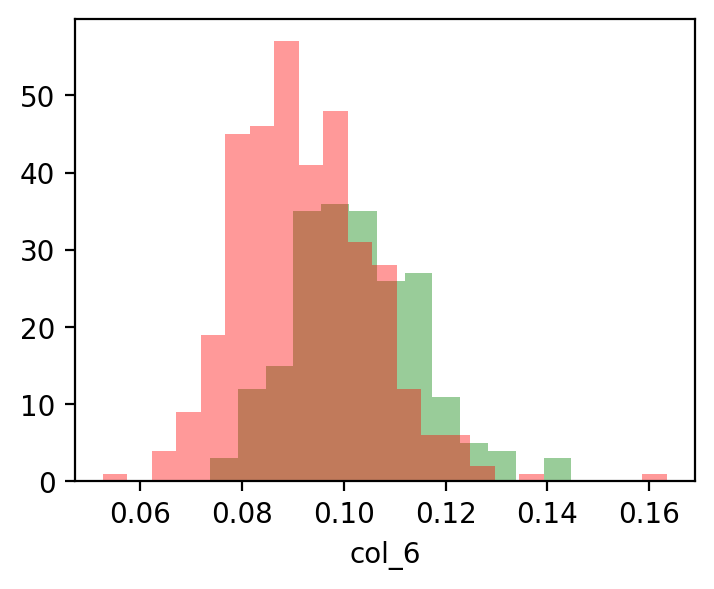

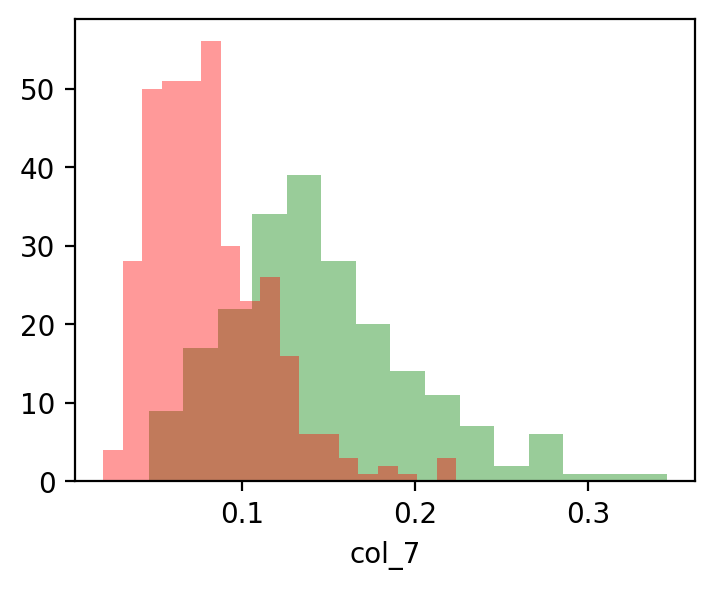

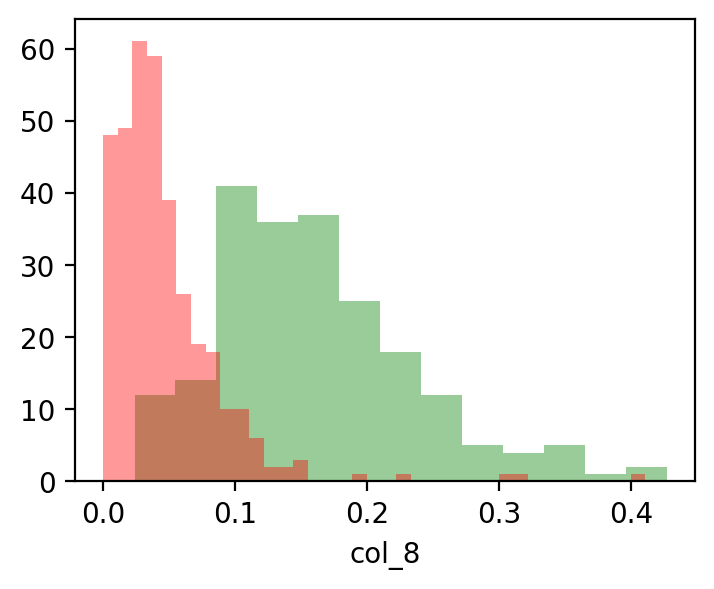

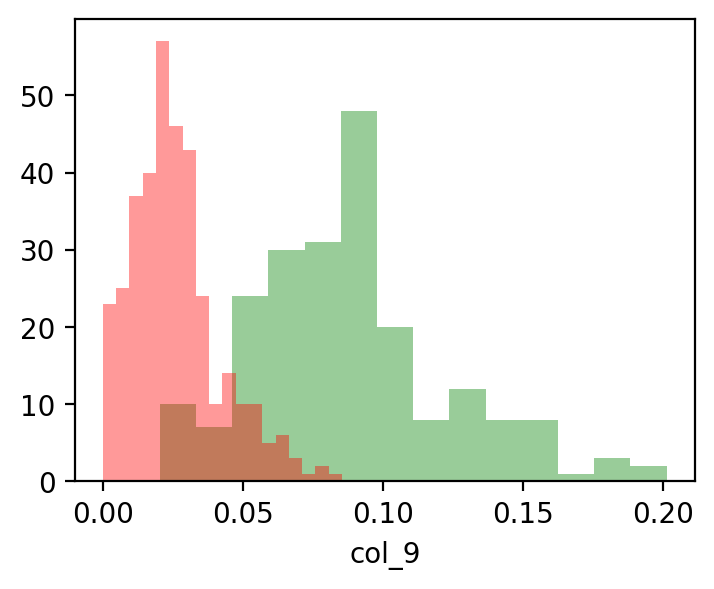

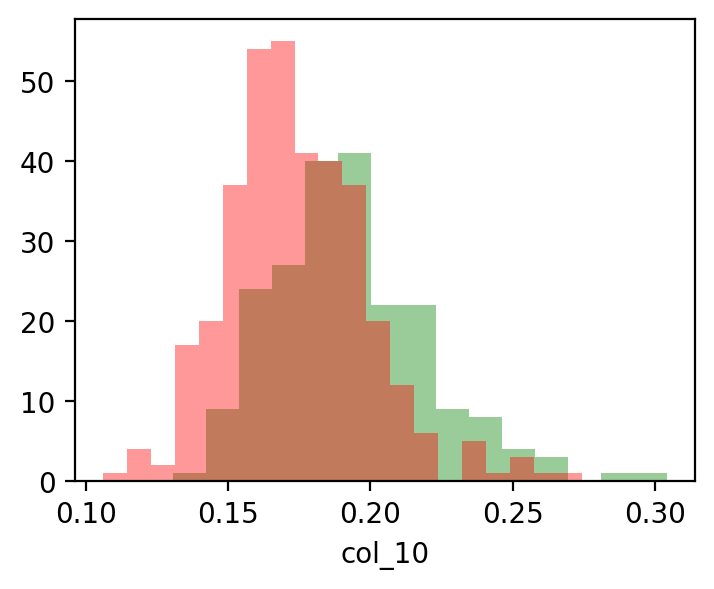

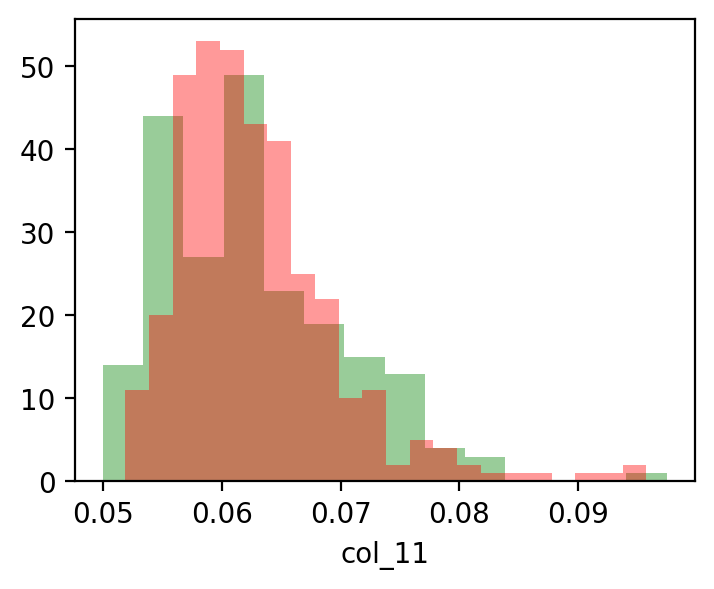

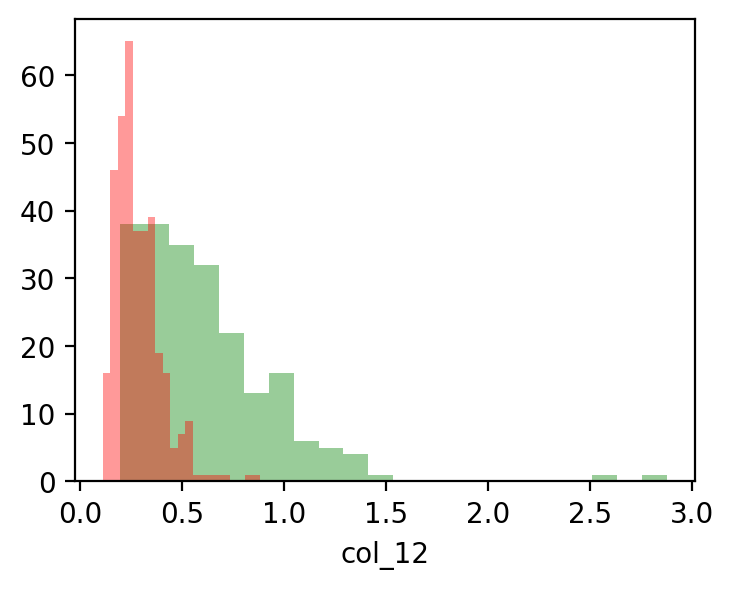

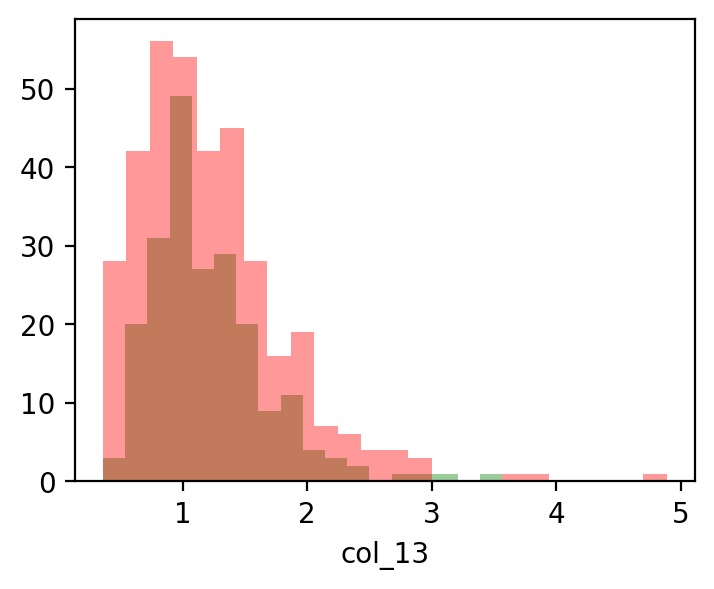

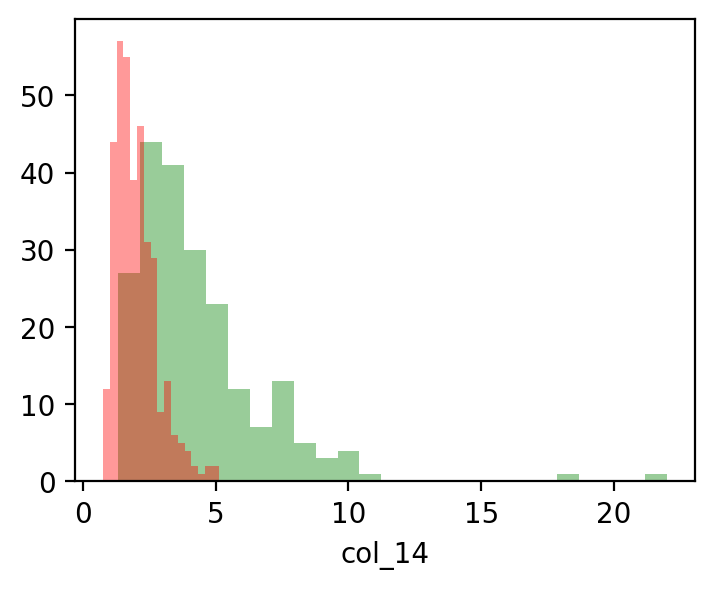

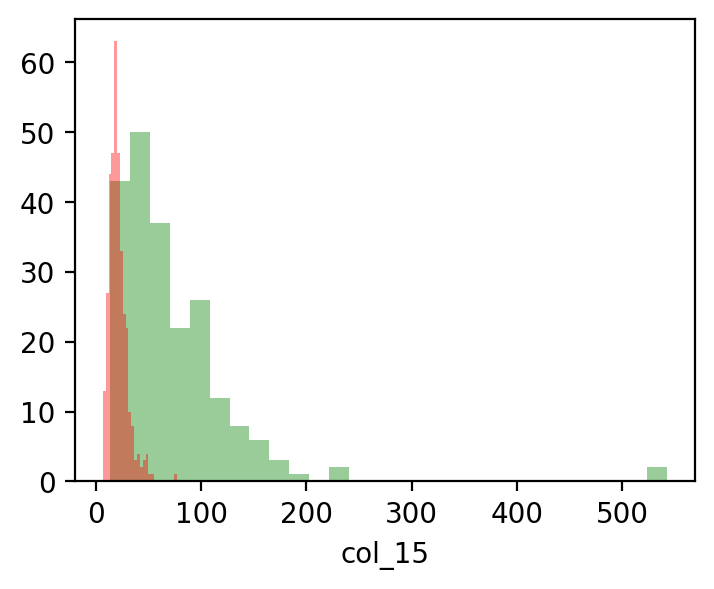

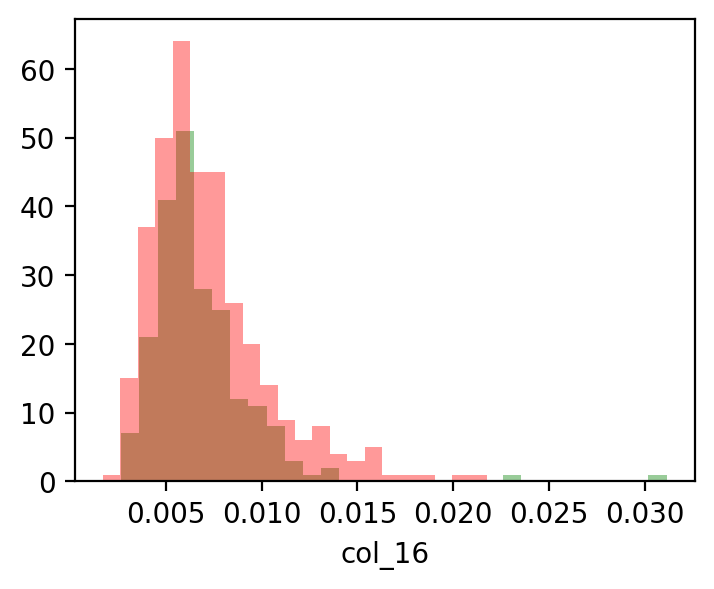

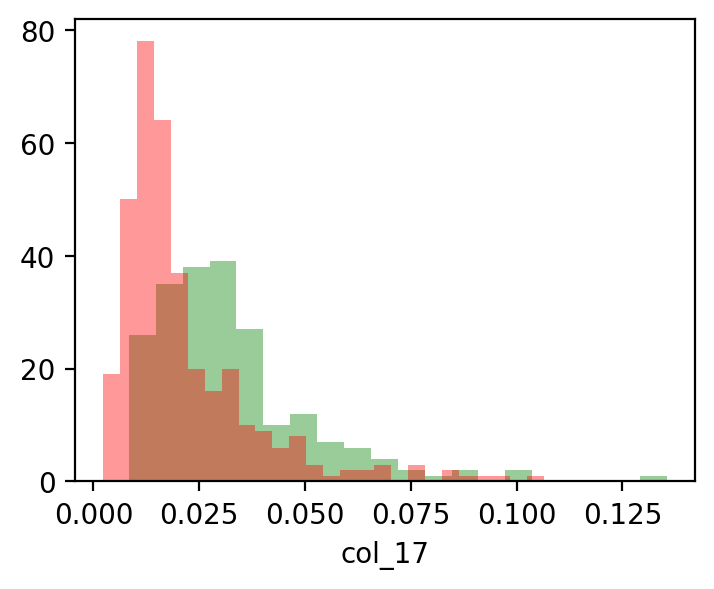

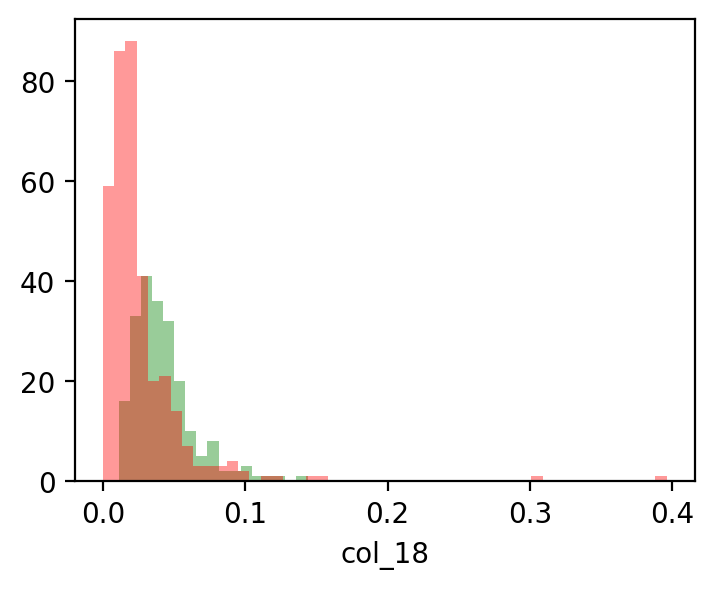

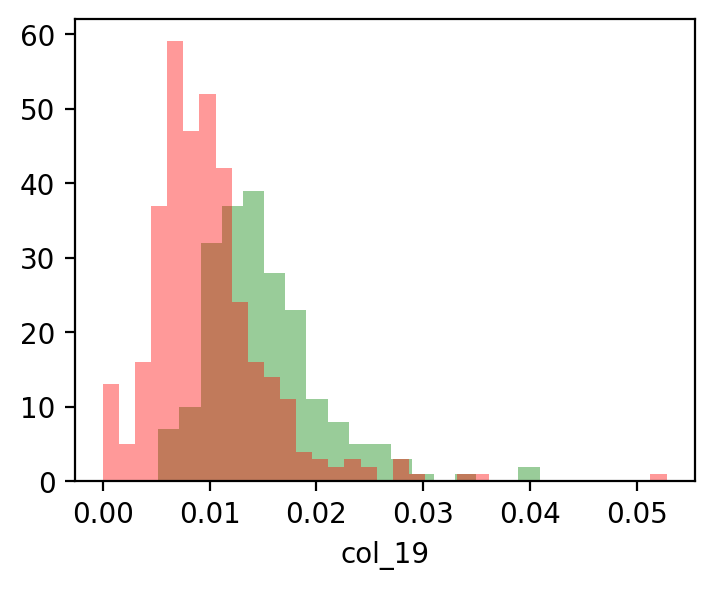

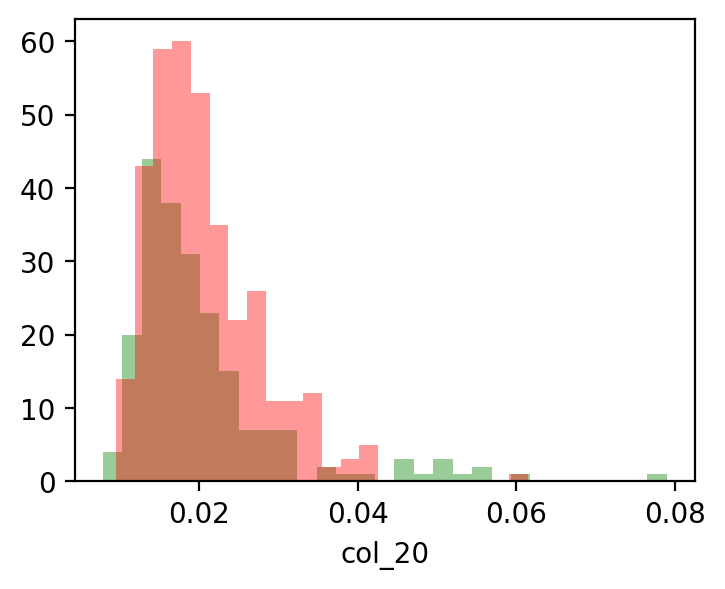

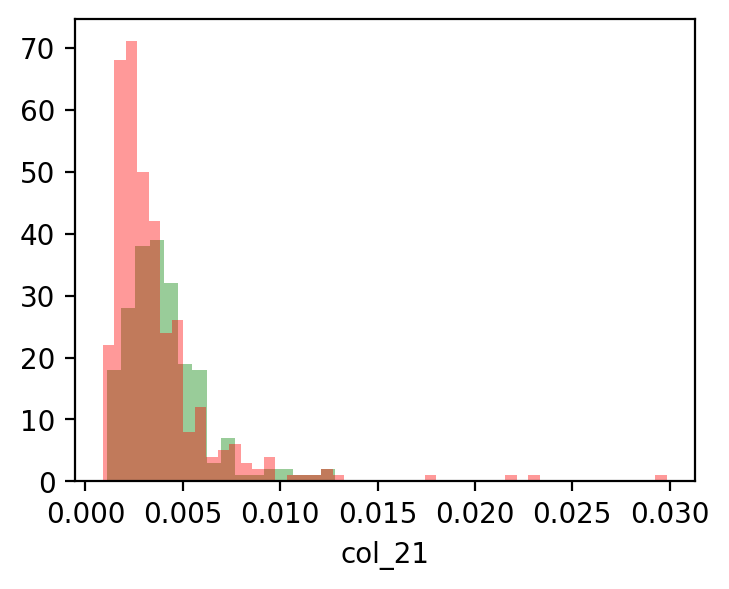

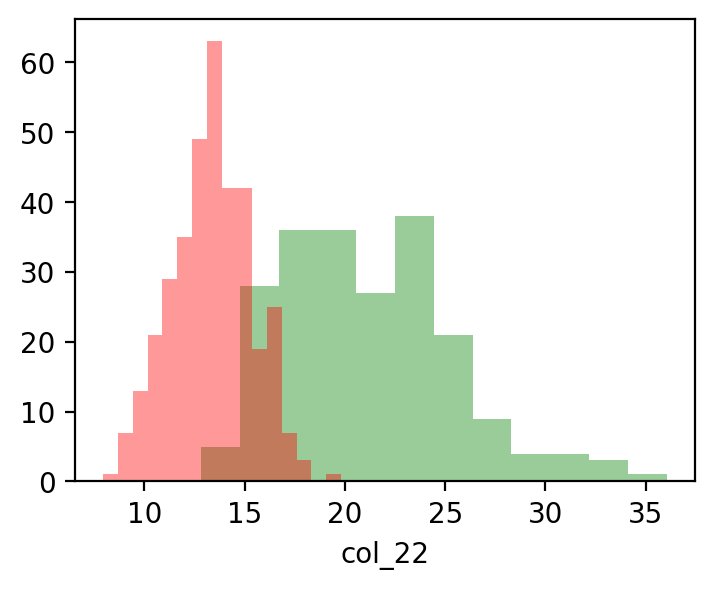

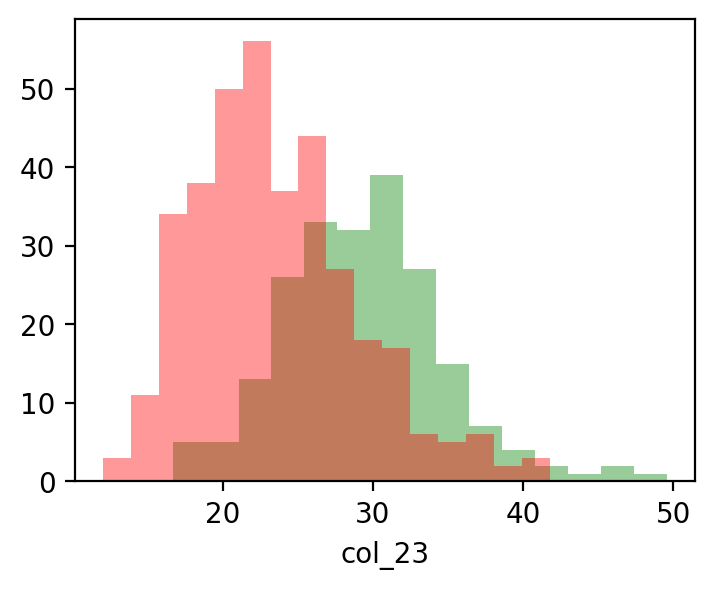

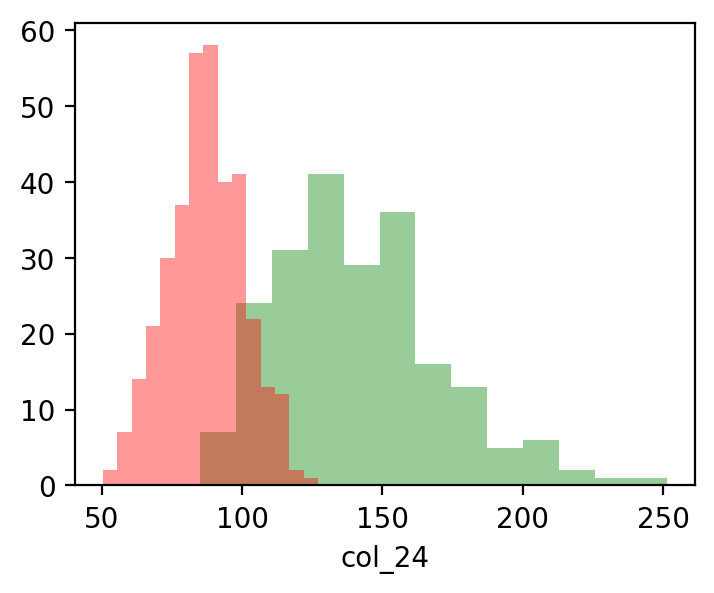

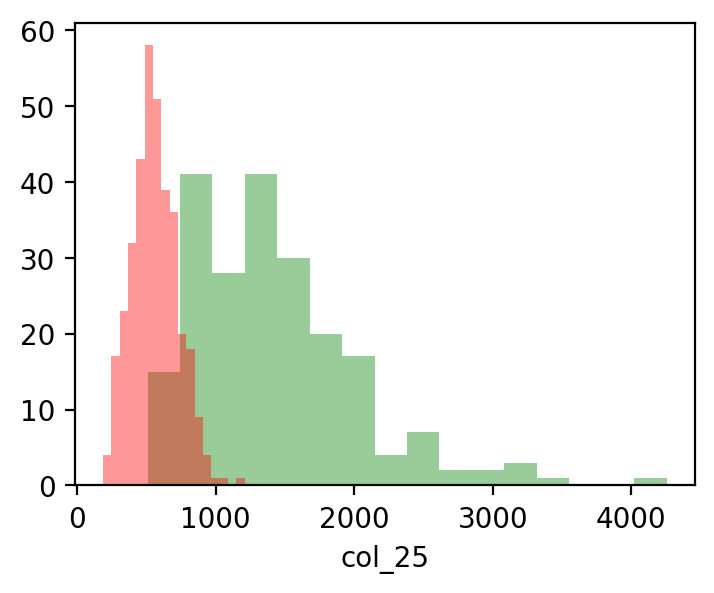

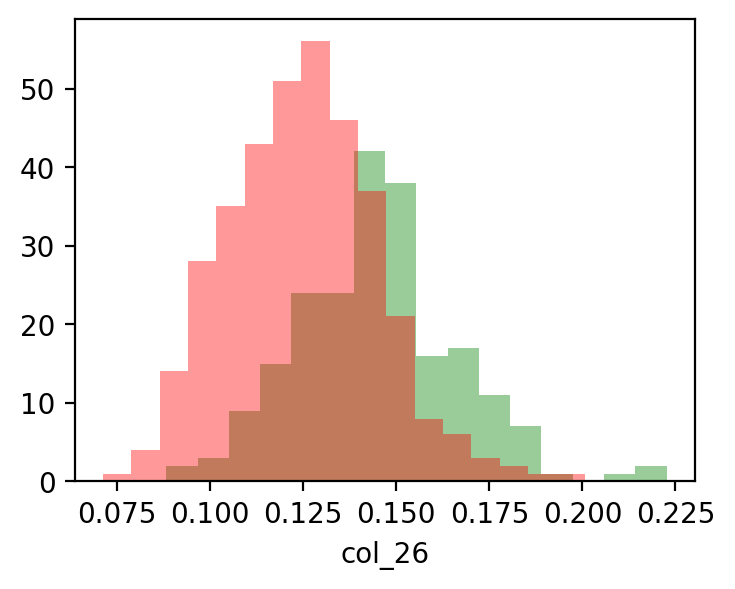

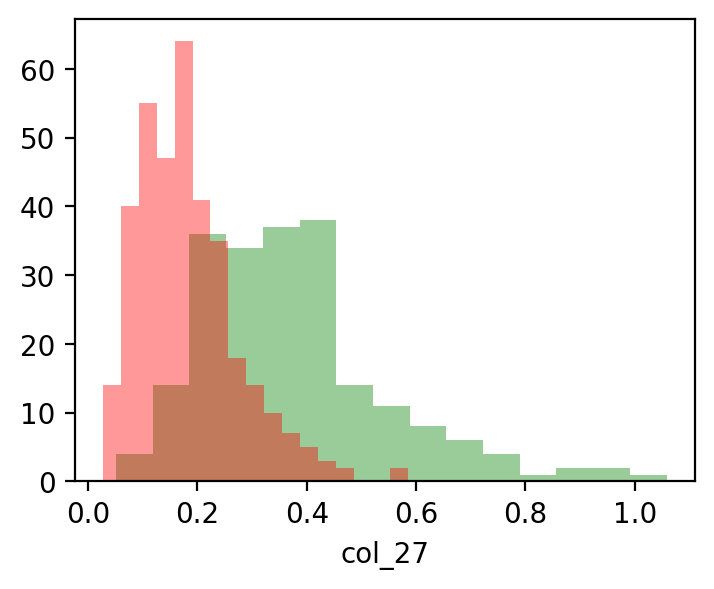

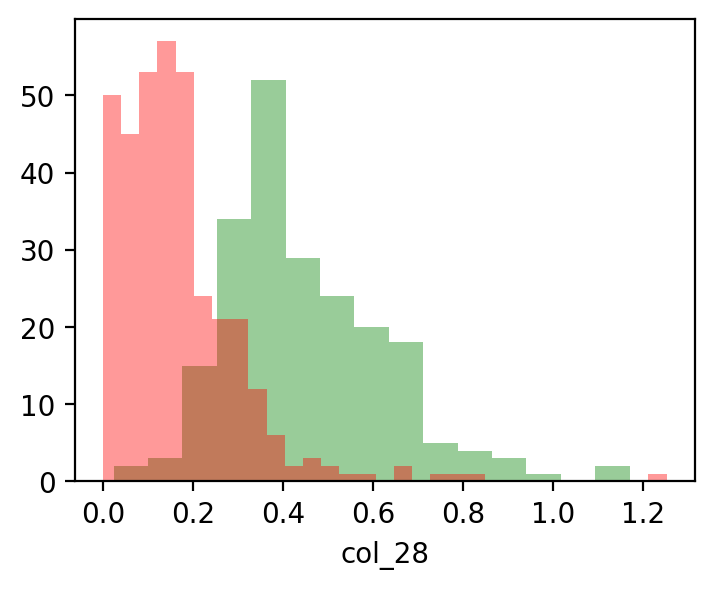

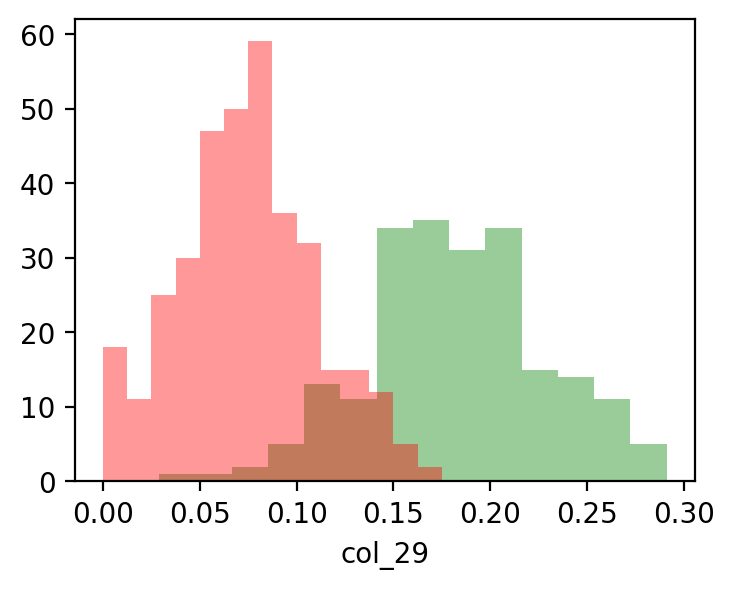

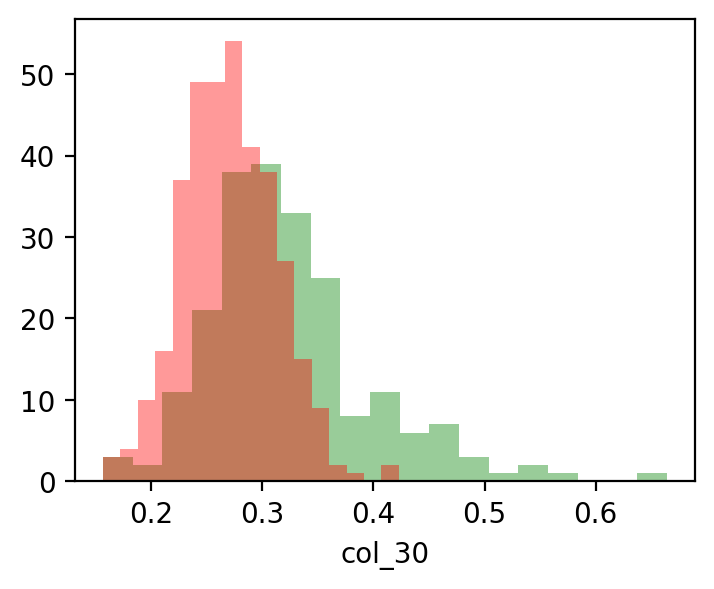

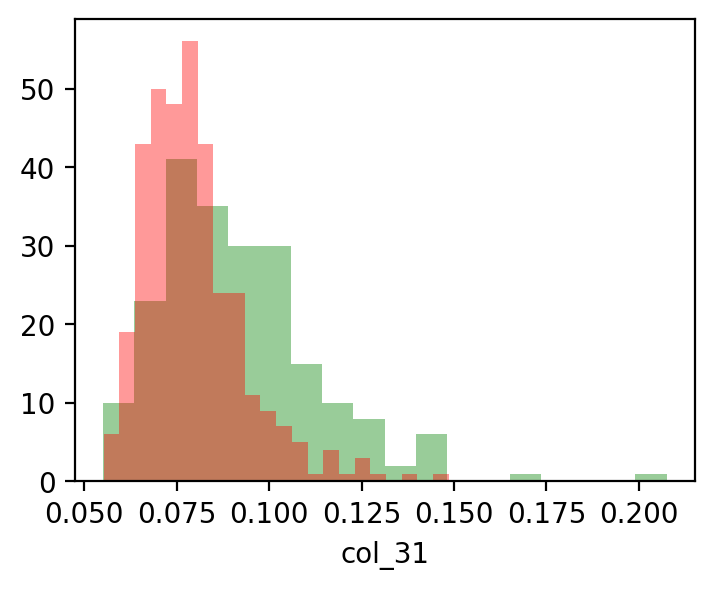

In [38]:
for col in df.drop("target", axis=1).columns:
    fig = plt.figure(figsize=(4, 3), dpi=200)
    sns.distplot(a=df[df["target"] == "M"][col], color="green", kde=False)
    sns.distplot(a=df[df["target"] == "B"][col], color="red", kde=False)

    plt.show()

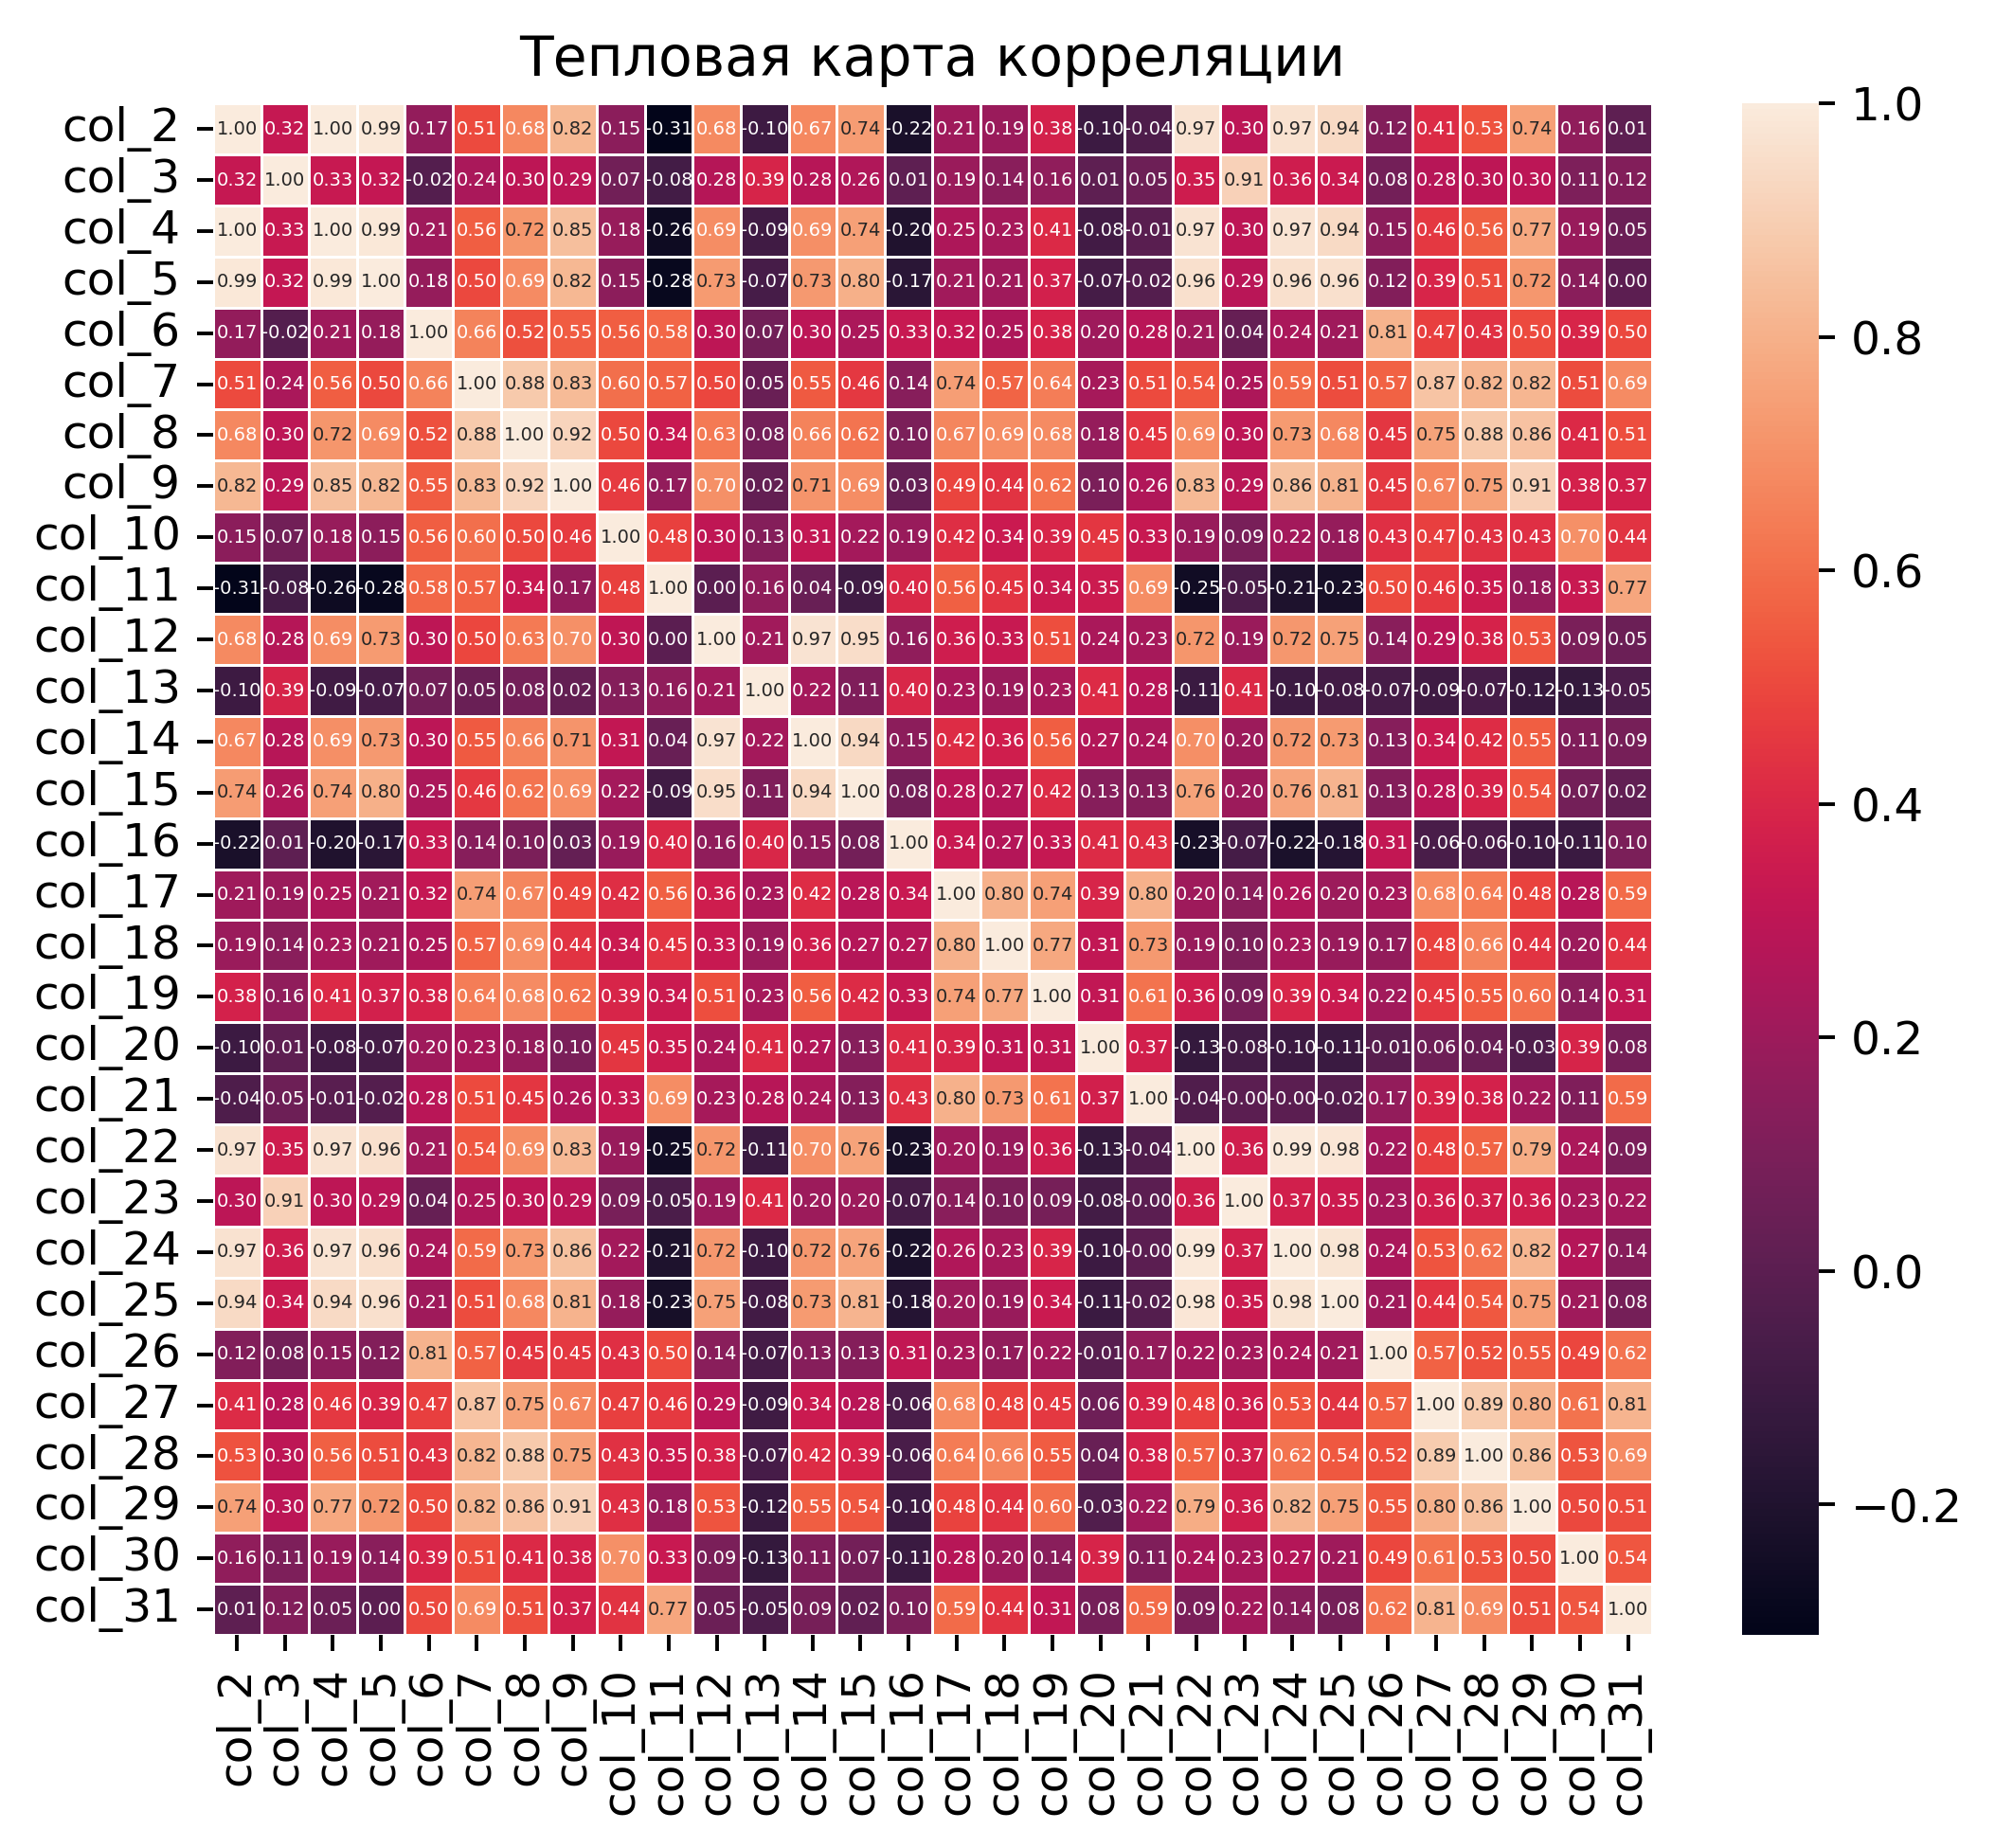

In [44]:
fig = plt.figure(figsize=(7, 6), dpi=350)
plt.title("Тепловая карта корреляции")

sns.heatmap(
    df.drop("target", axis=1).corr(),
    annot=True,
    linewidths=0.25,
    annot_kws={"size": 4},  
    fmt=".2f", 
)

plt.show()

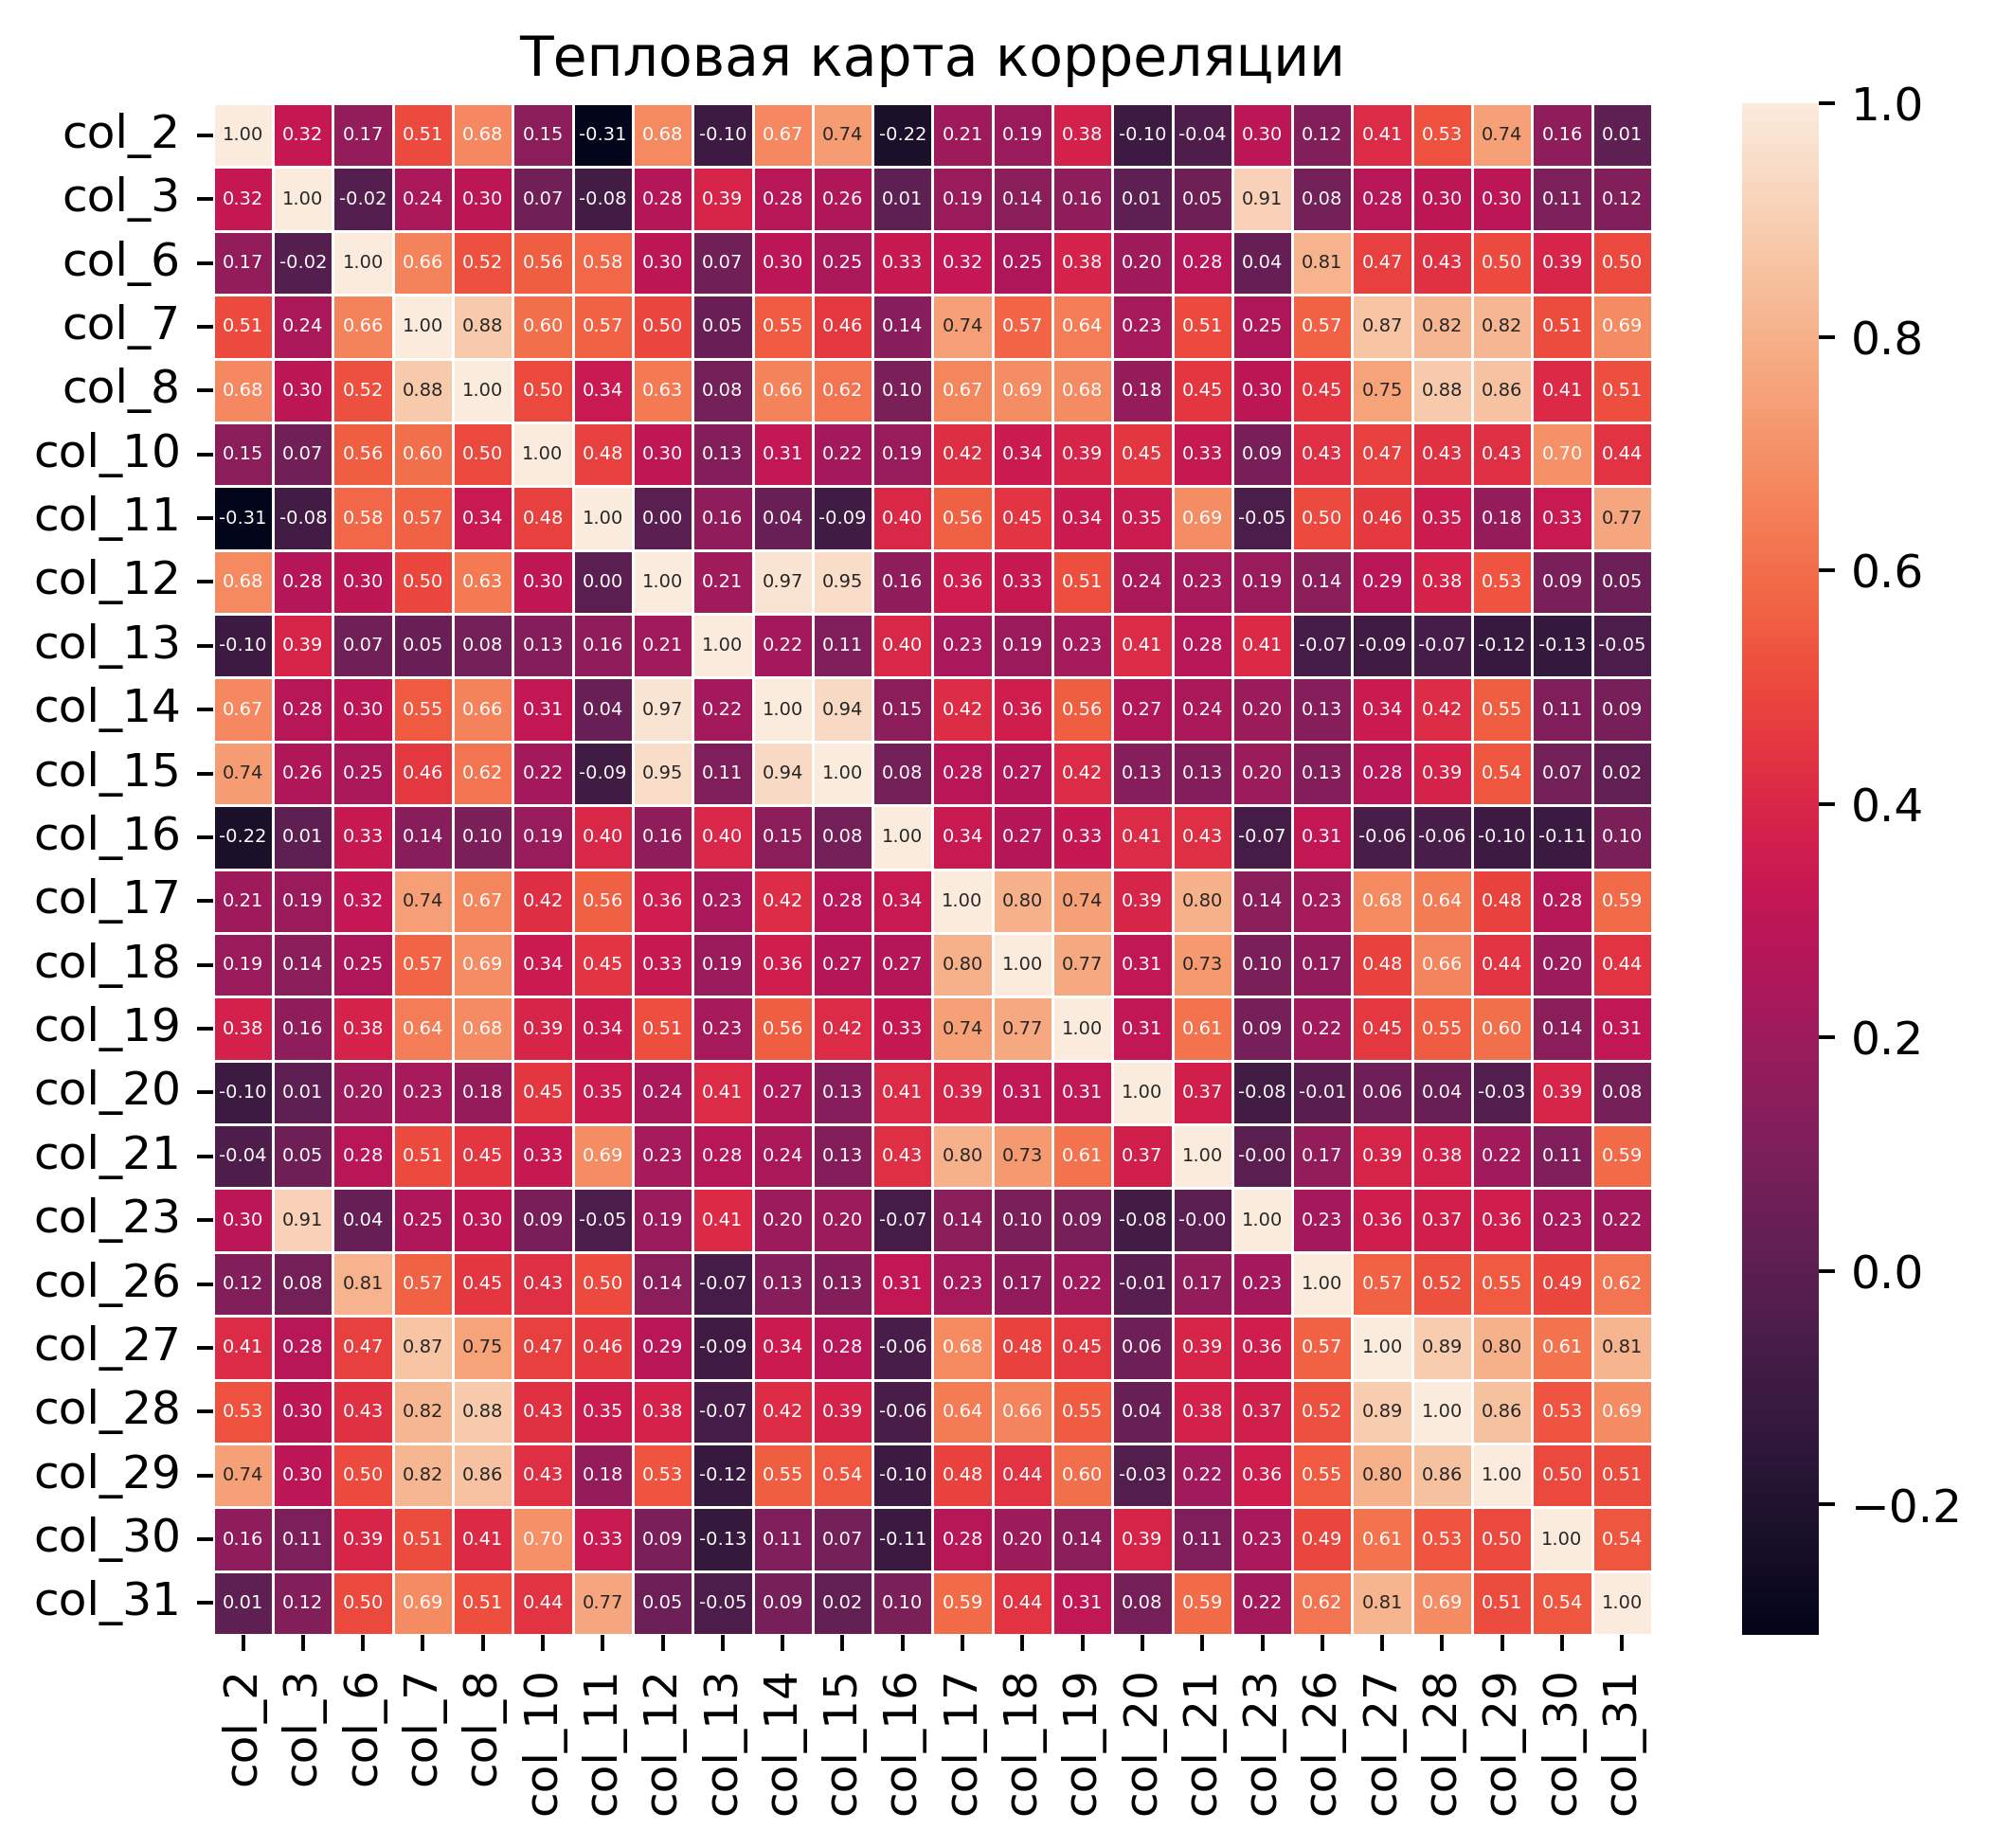

In [47]:
fig = plt.figure(figsize=(7, 6), dpi=350)
plt.title("Тепловая карта корреляции")

sns.heatmap(
    df.drop(["target", "col_4", "col_5", "col_9", "col_22", "col_24", "col_25"], axis=1).corr(),
    annot=True,
    linewidths=0.25,
    annot_kws={"size": 4},  
    fmt=".2f", 
)

plt.show()

In [63]:
# 1. Отбираем только числовые признаки без таргета
X = df.drop(["target", "col_2", "col_22", "col_4", "col_24", "col_11", "col_26", "col_23", "col_31", "col_30", "col_8", "col_12", "col_29", "col_6"], axis=1)

# Убедимся, что нет пропусков и все типы числовые (float)
X = X.select_dtypes(include=[np.number]).dropna()

# 2. Создаем датафрейм для результатов VIF
vif_df = pd.DataFrame()
vif_df["Feature"] = X.columns

# 3. Считаем VIF для каждого столбца
vif_df["VIF"] = [
    variance_inflation_factor(X.values, i) for i in range(X.shape[1])
]

# 4. Сортируем по убыванию (сверху будут самые коллинеарные)
vif_df = vif_df.sort_values(by="VIF", ascending=False).reset_index(drop=True)

print(vif_df)

   Feature        VIF
0    col_7  74.723145
1    col_5  68.064164
2   col_27  67.808431
3   col_25  60.283045
4   col_28  49.557466
5   col_10  46.832291
6   col_14  45.119253
7    col_9  38.351637
8    col_3  31.178528
9   col_17  30.644778
10  col_15  28.196948
11  col_19  23.006881
12  col_18  21.113317
13  col_20  14.367698
14  col_21  12.158572
15  col_13  11.404865
16  col_16  10.610302


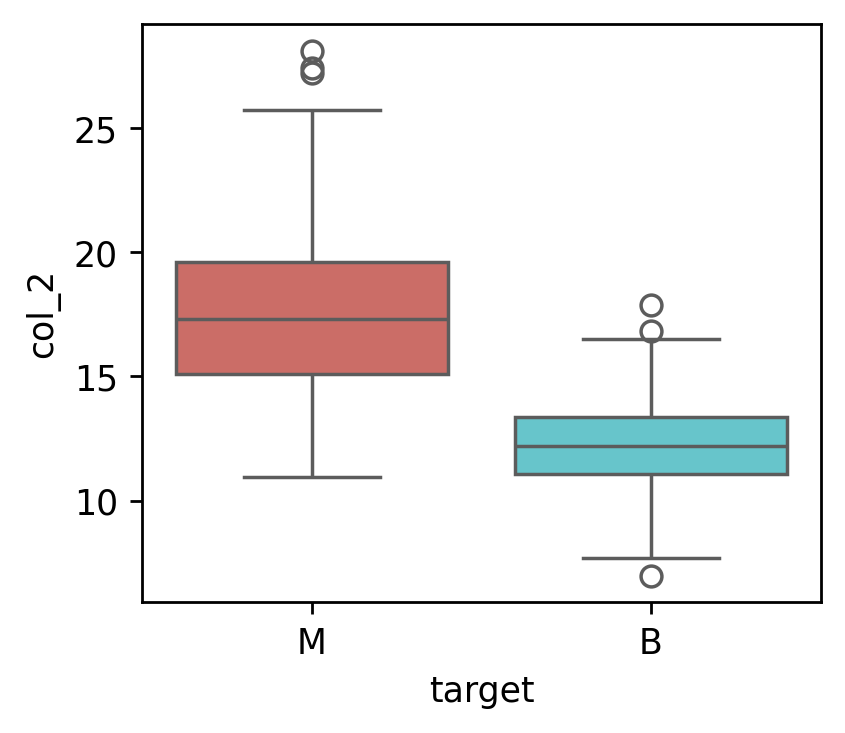

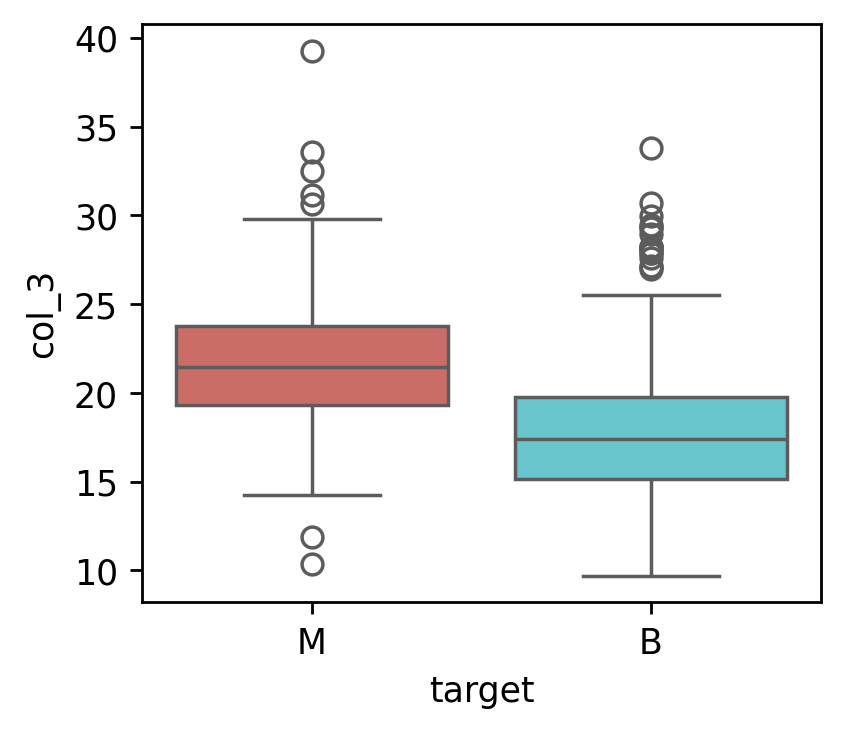

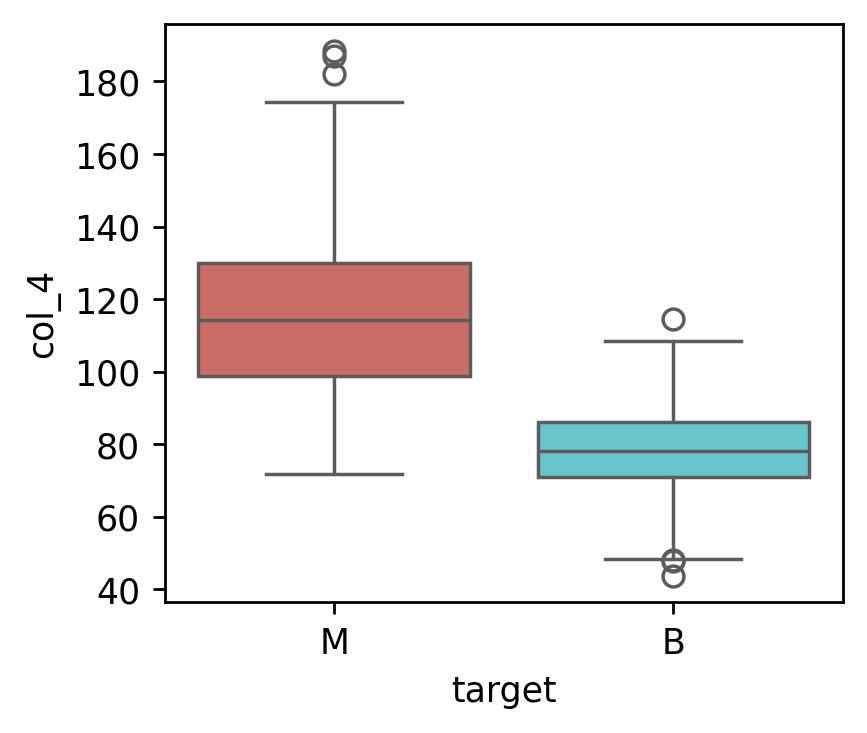

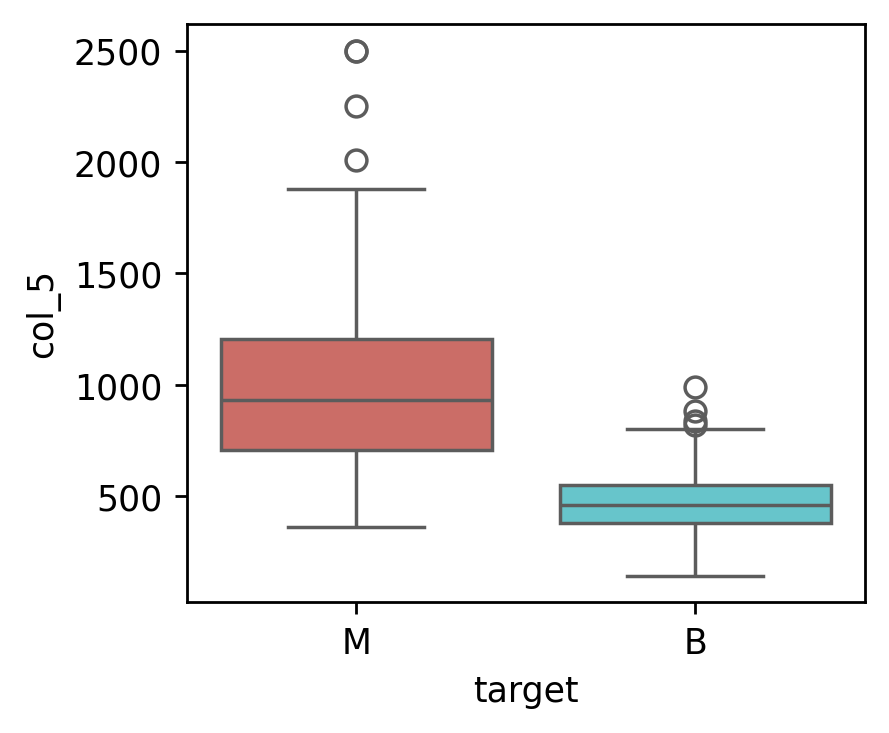

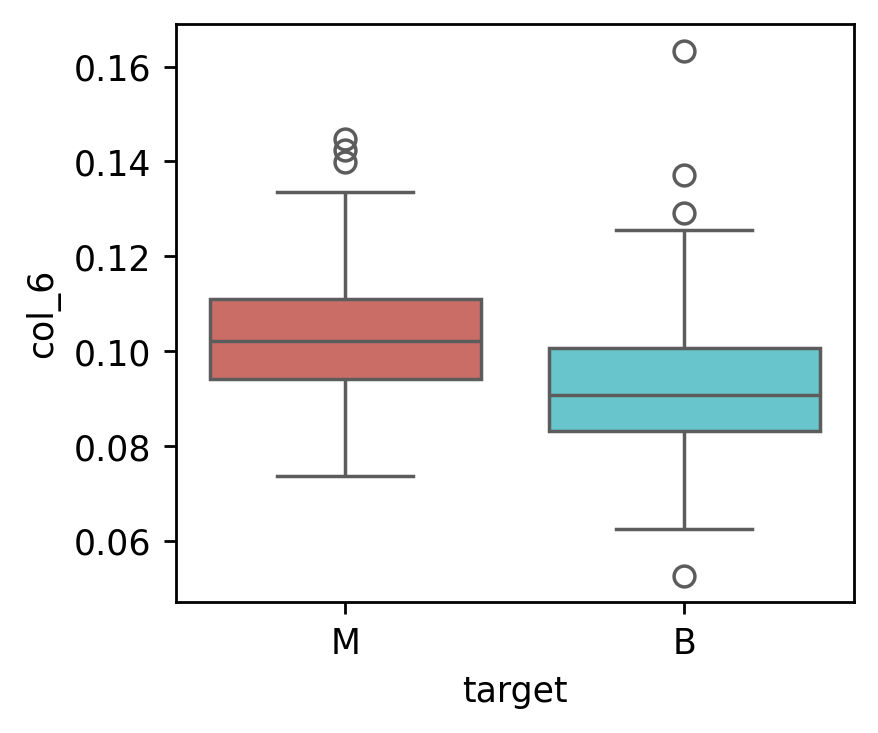

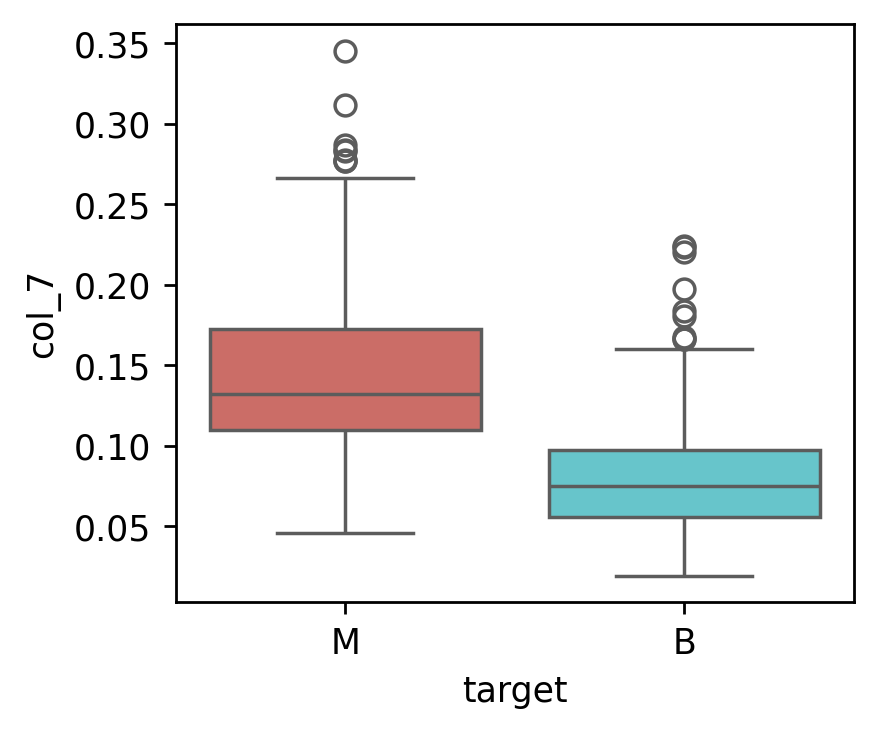

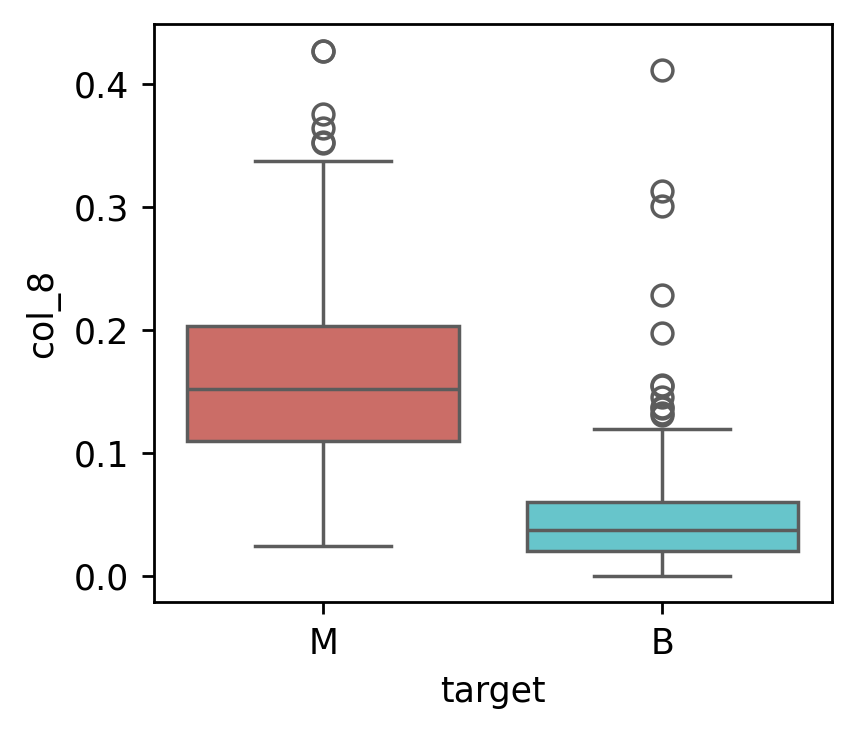

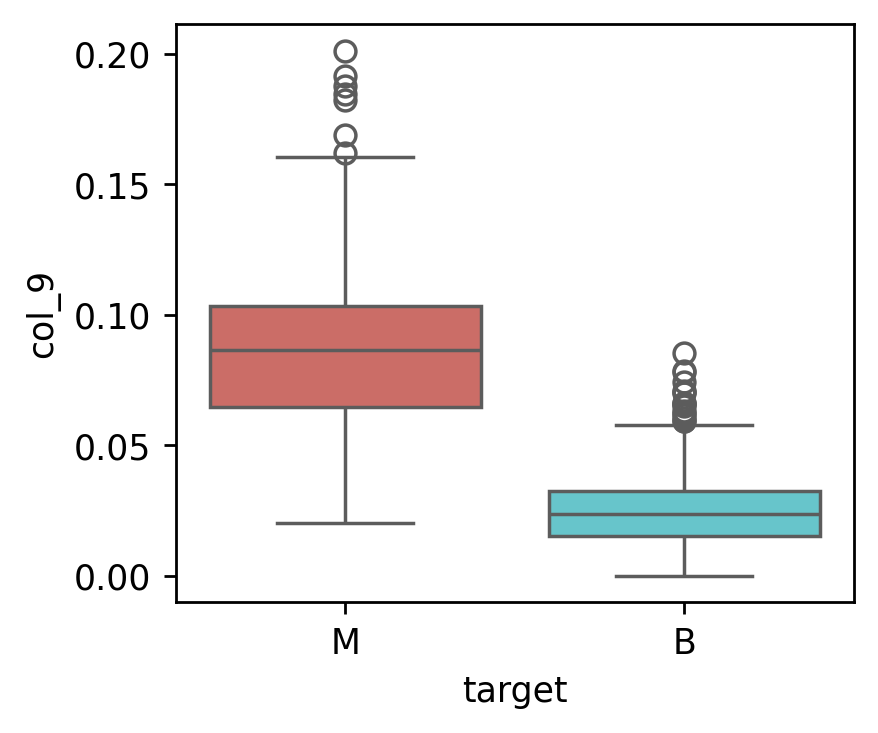

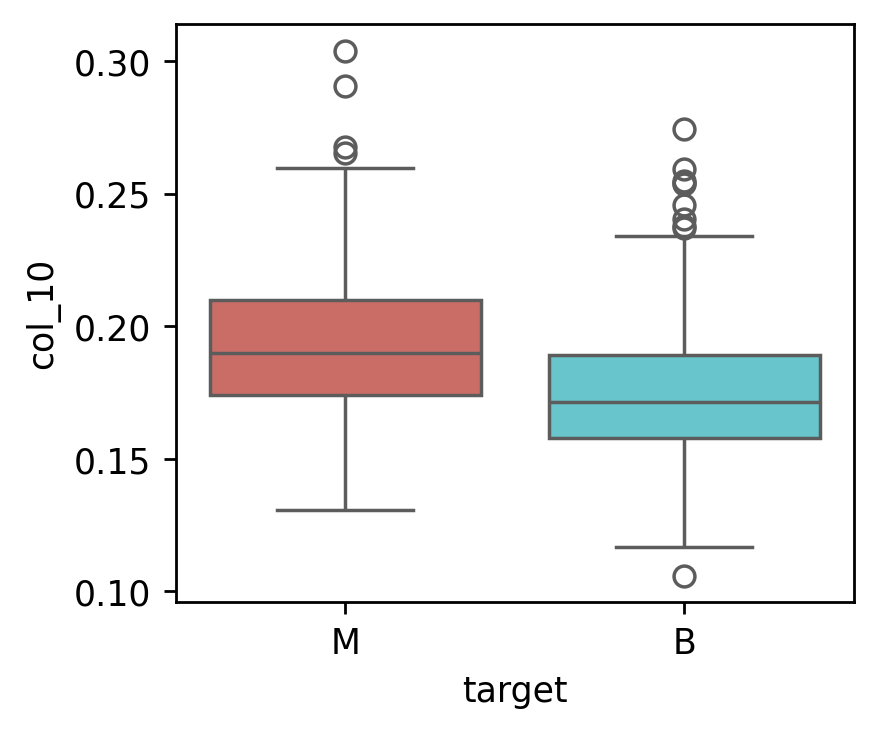

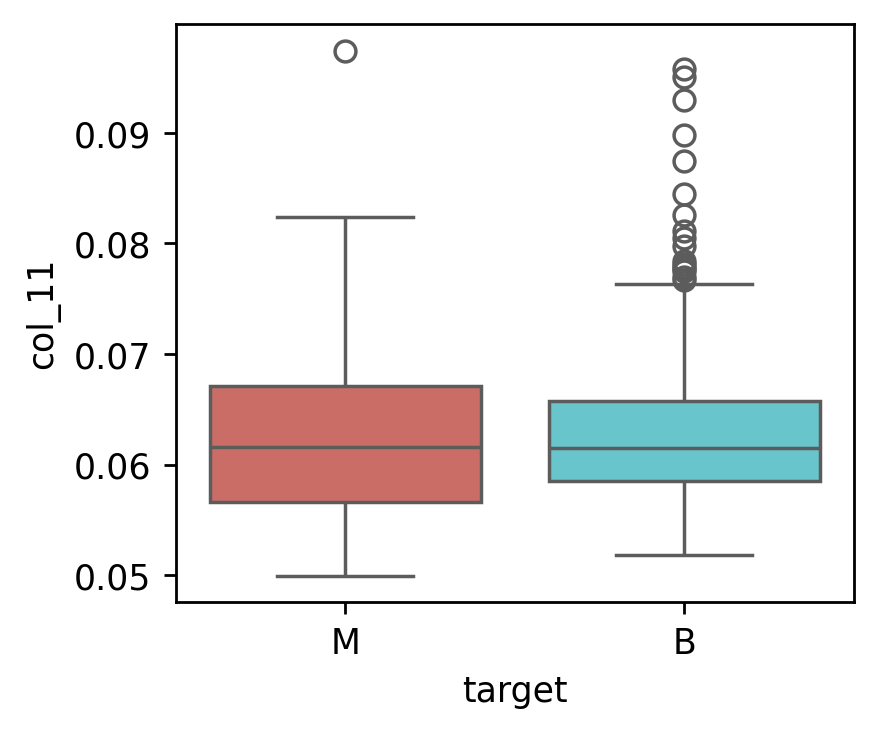

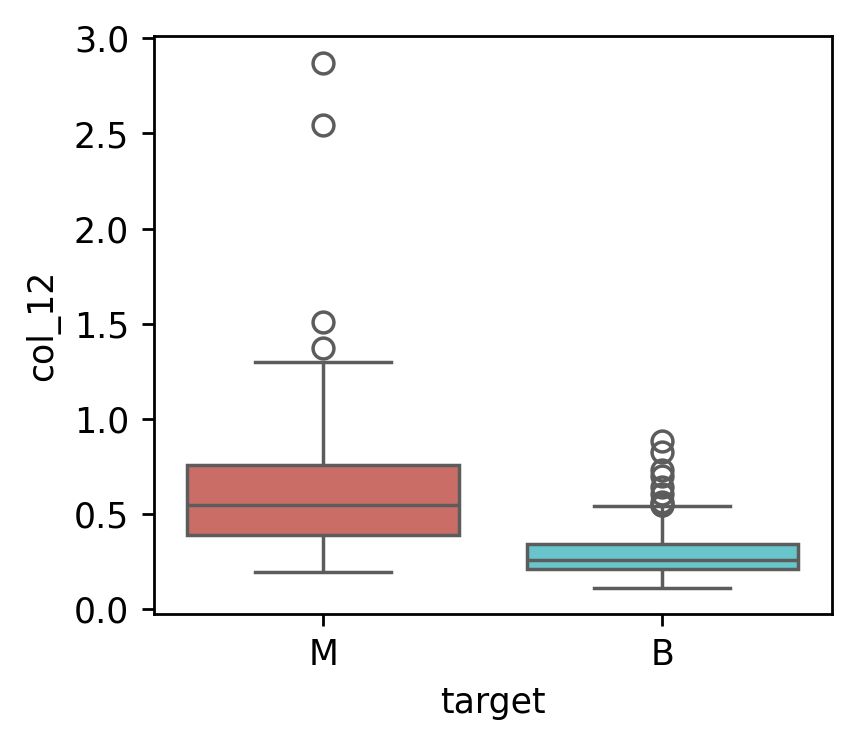

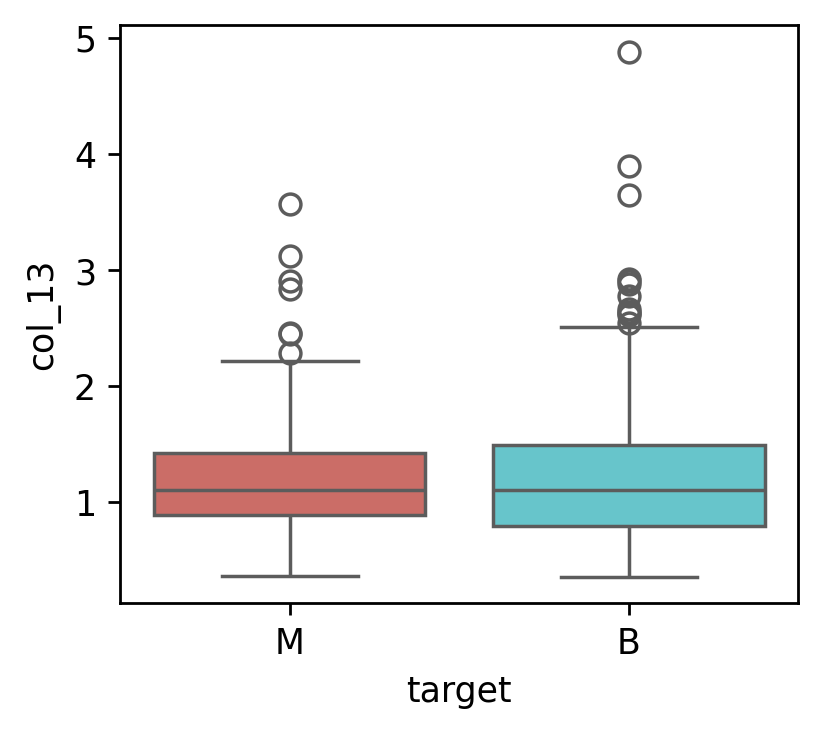

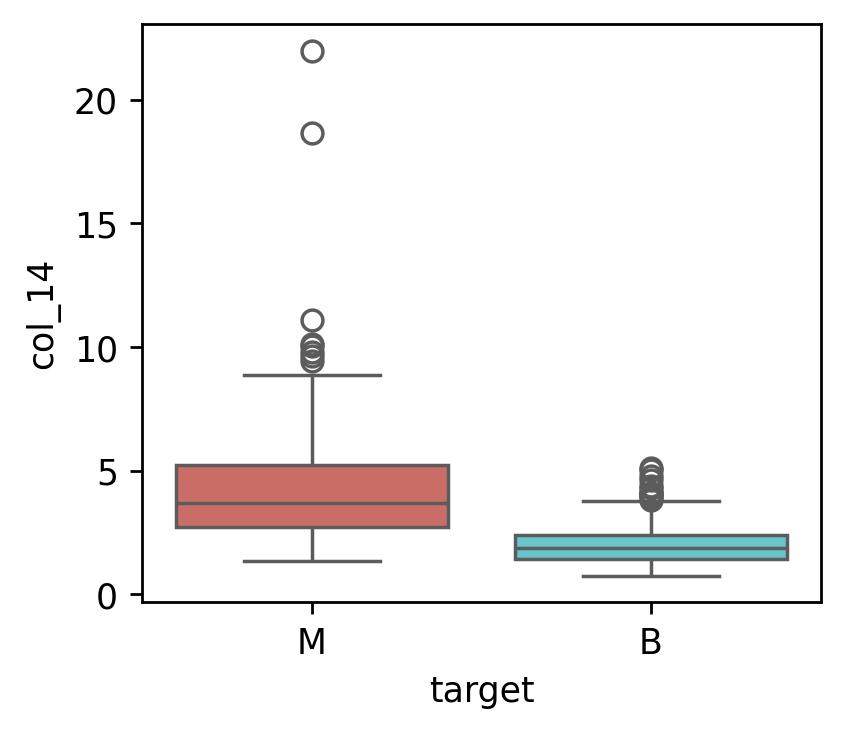

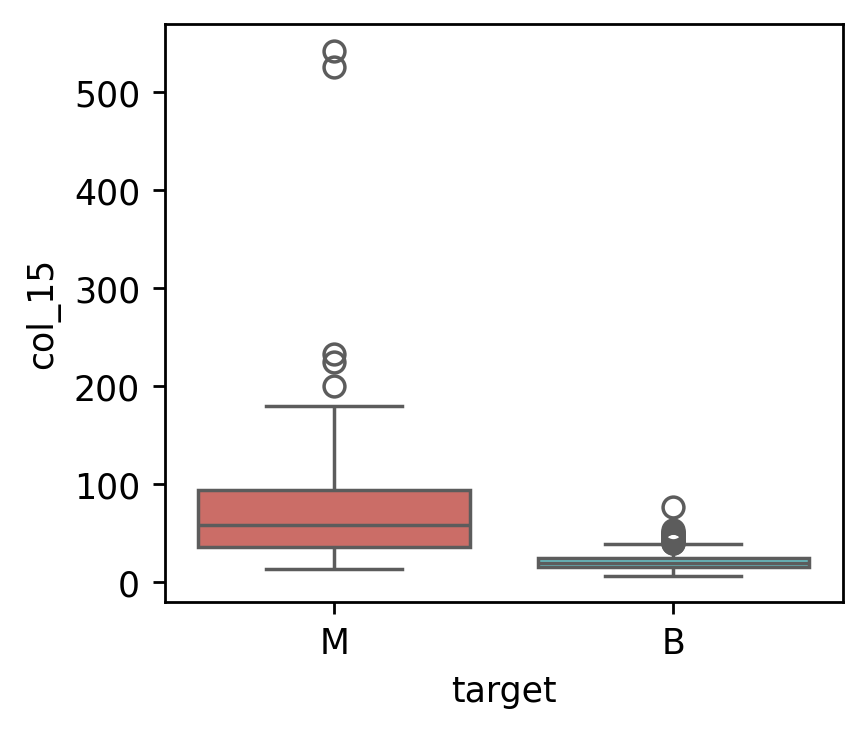

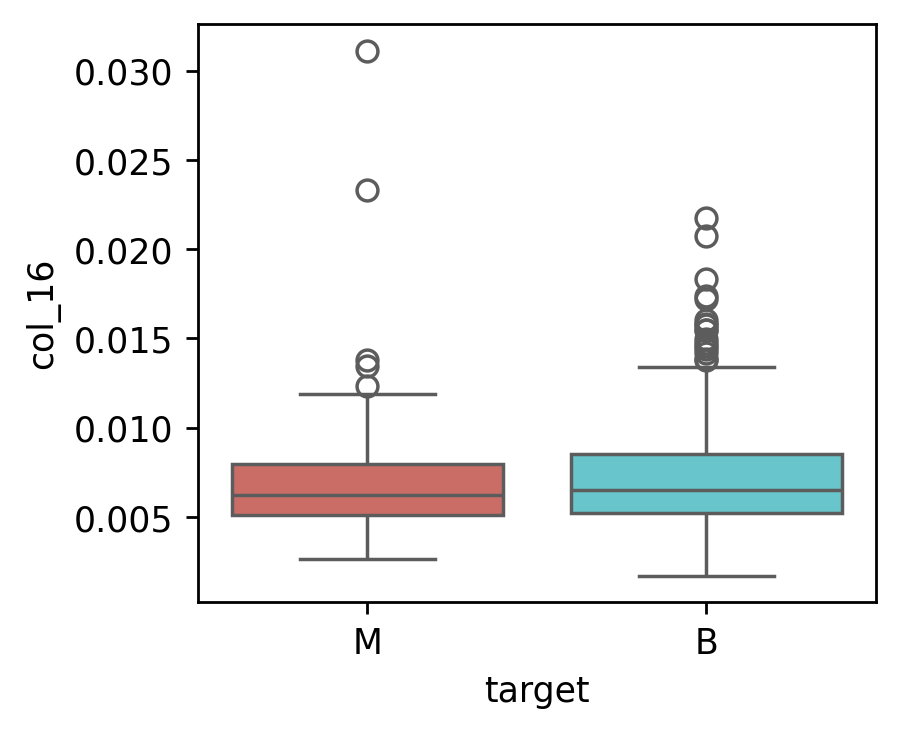

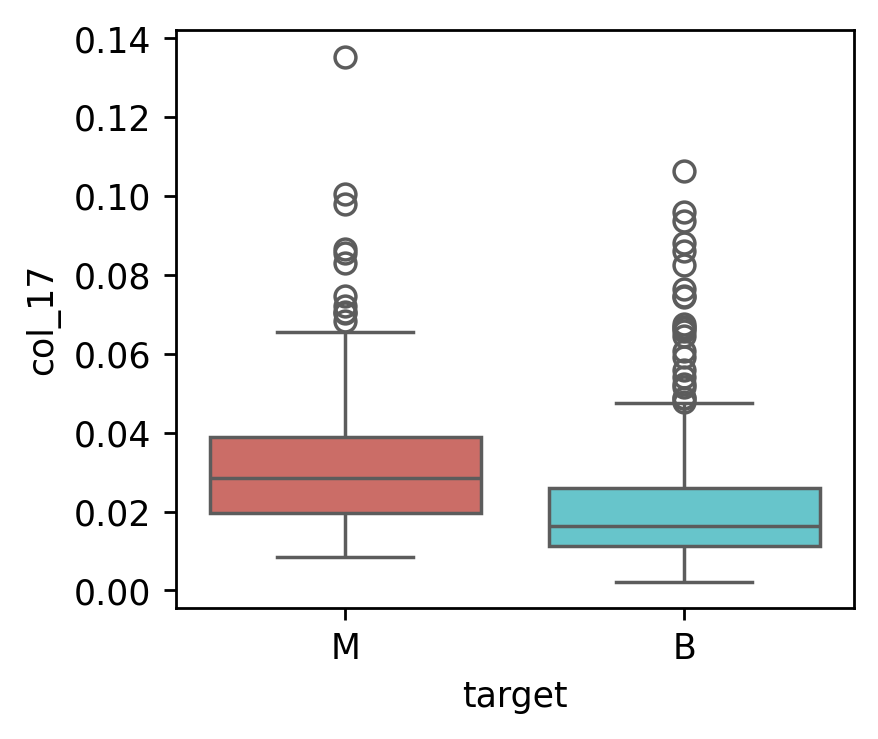

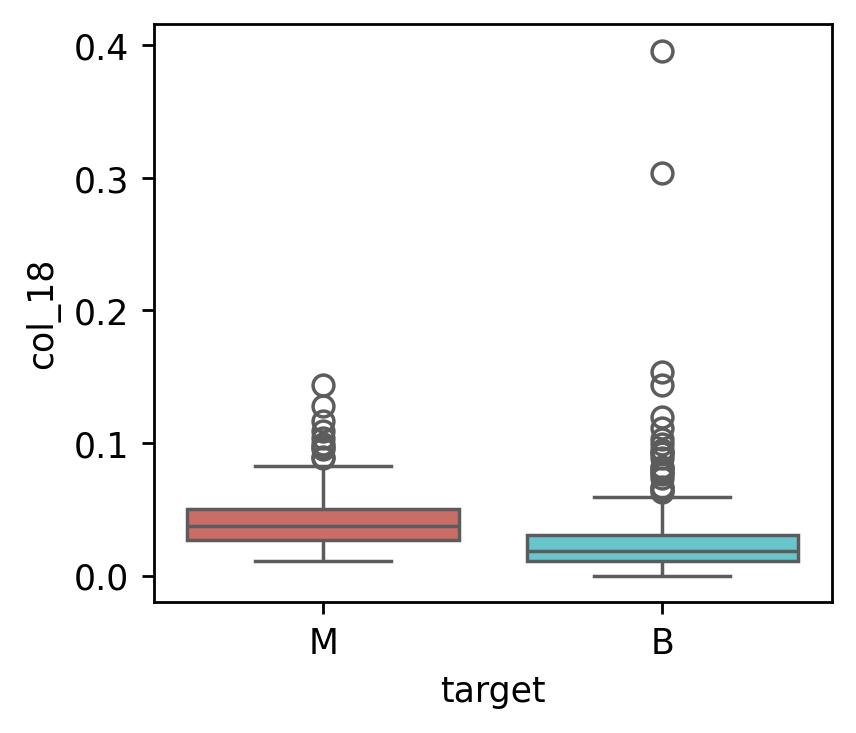

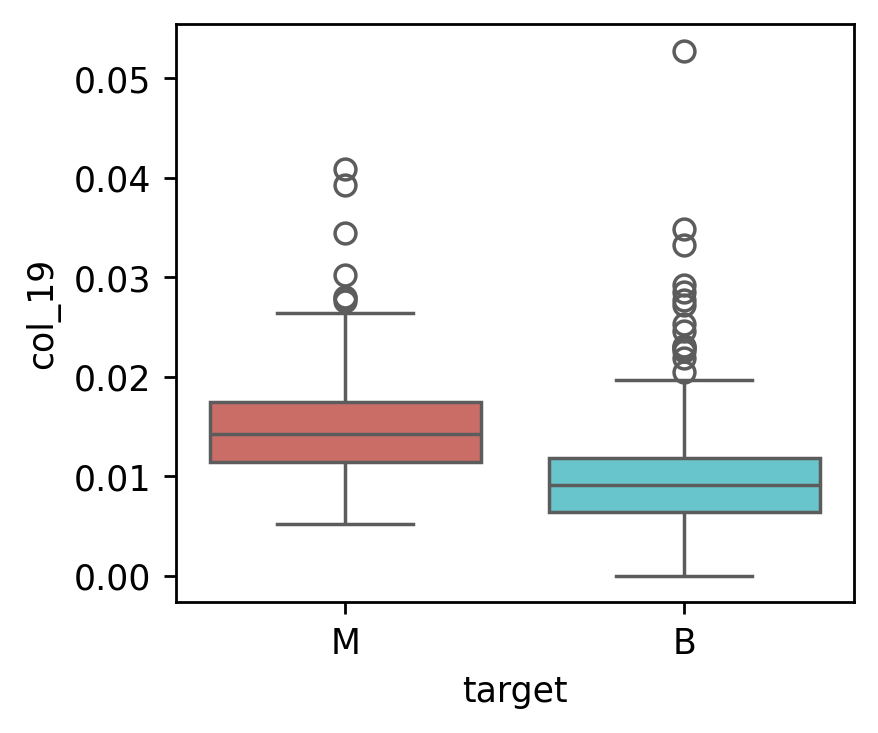

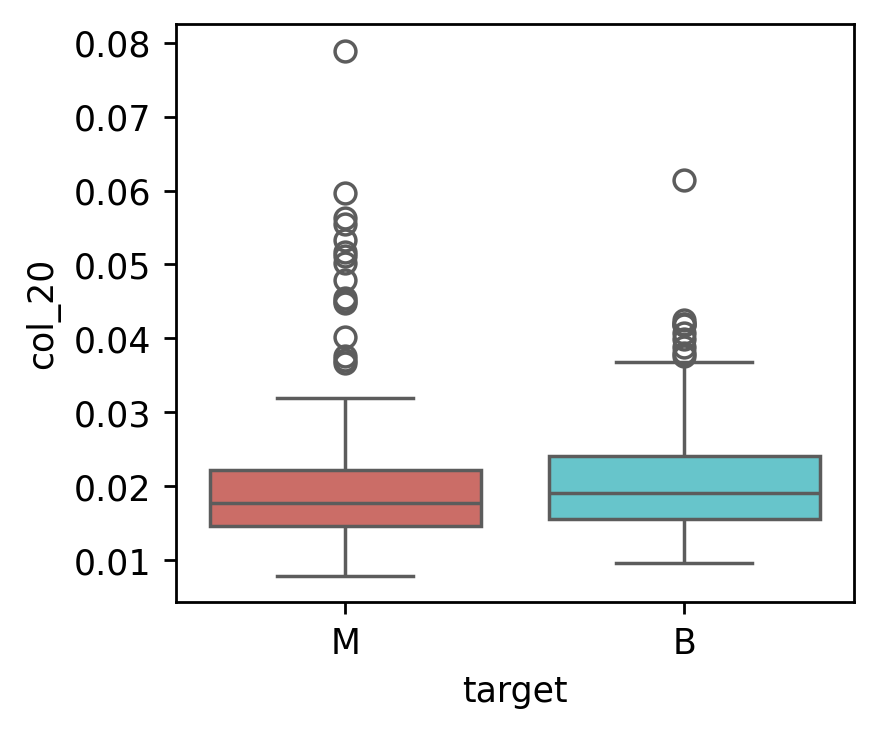

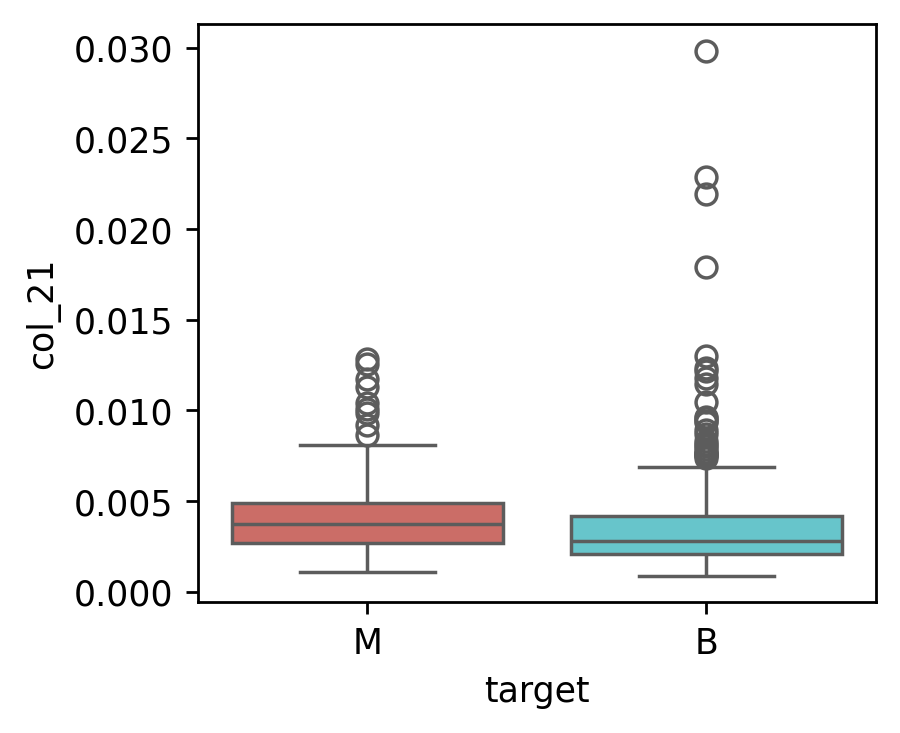

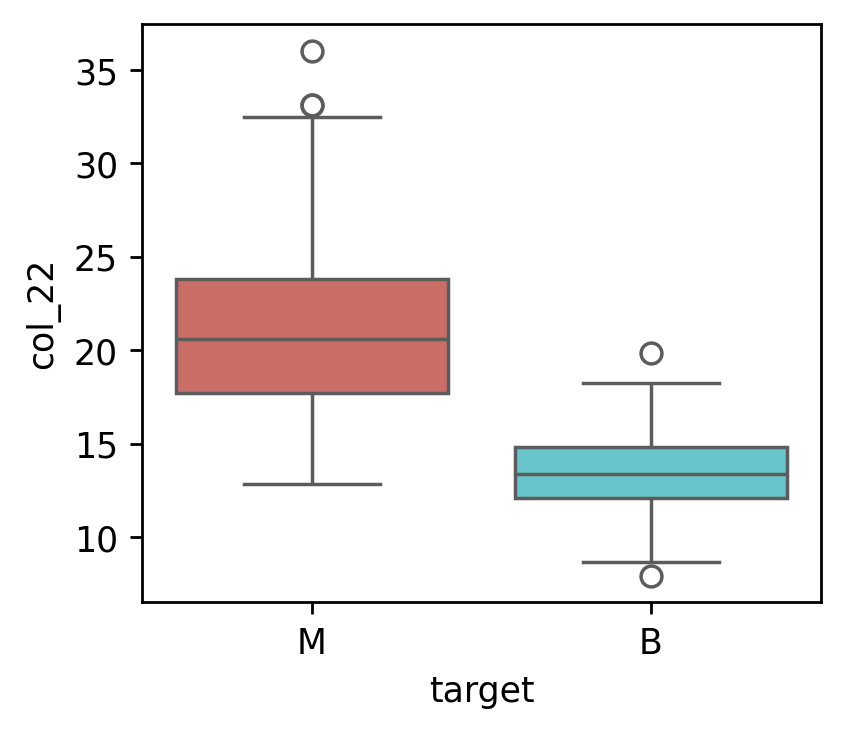

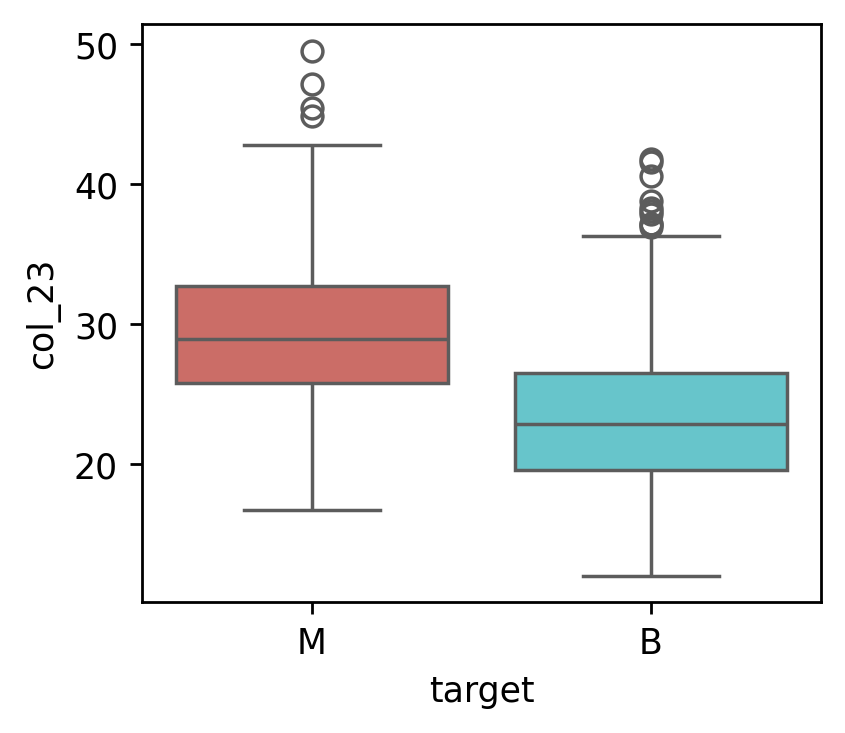

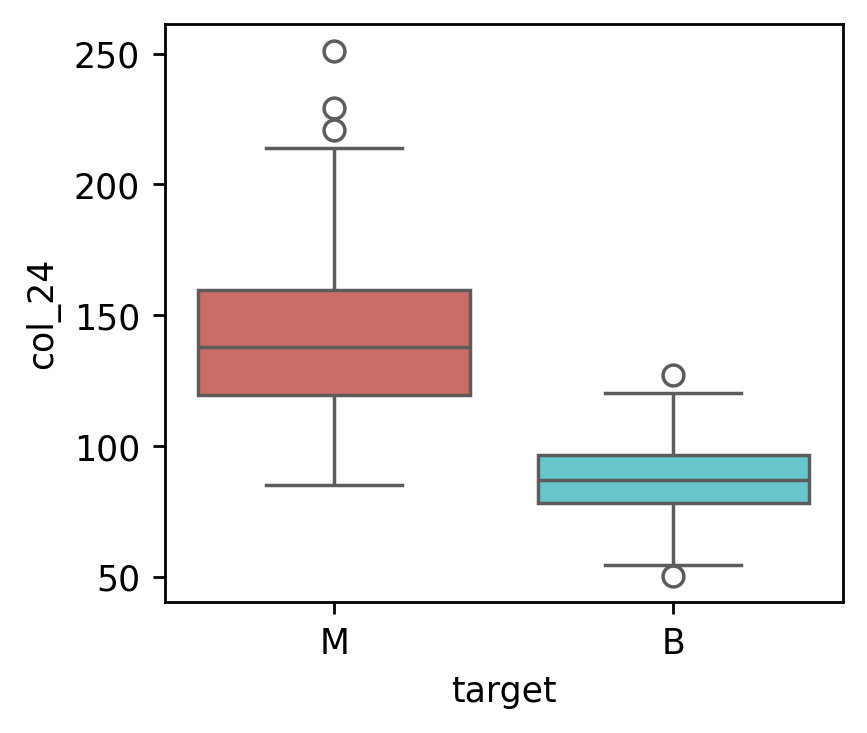

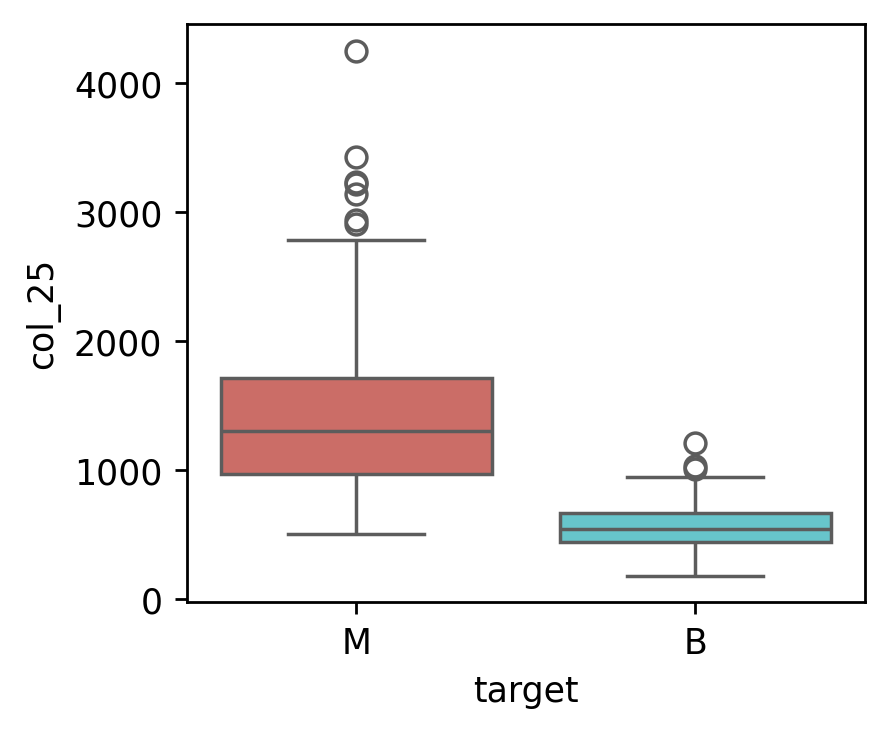

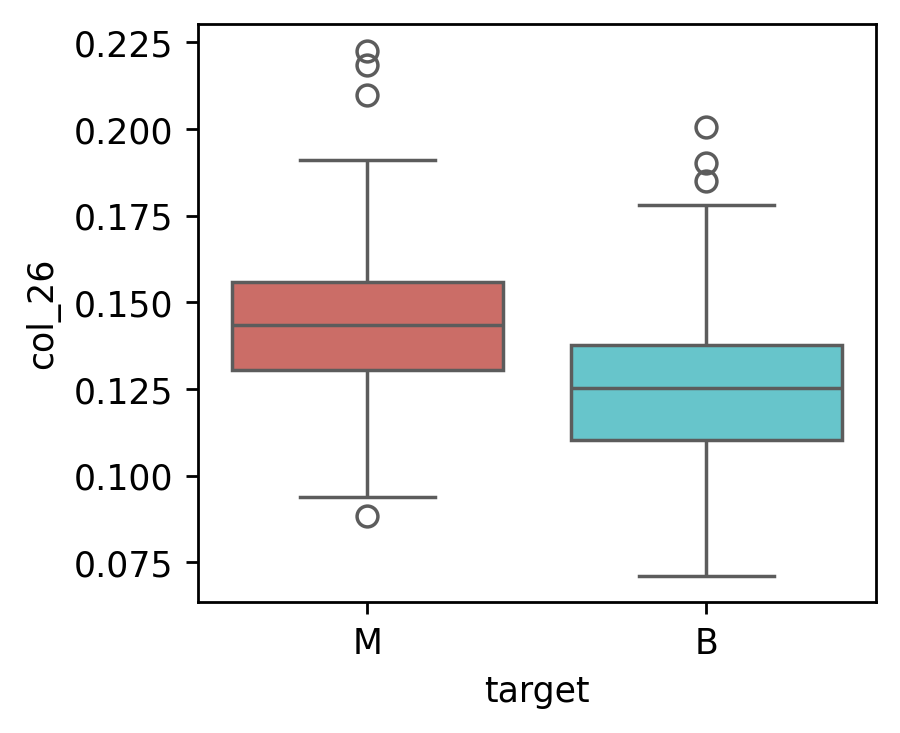

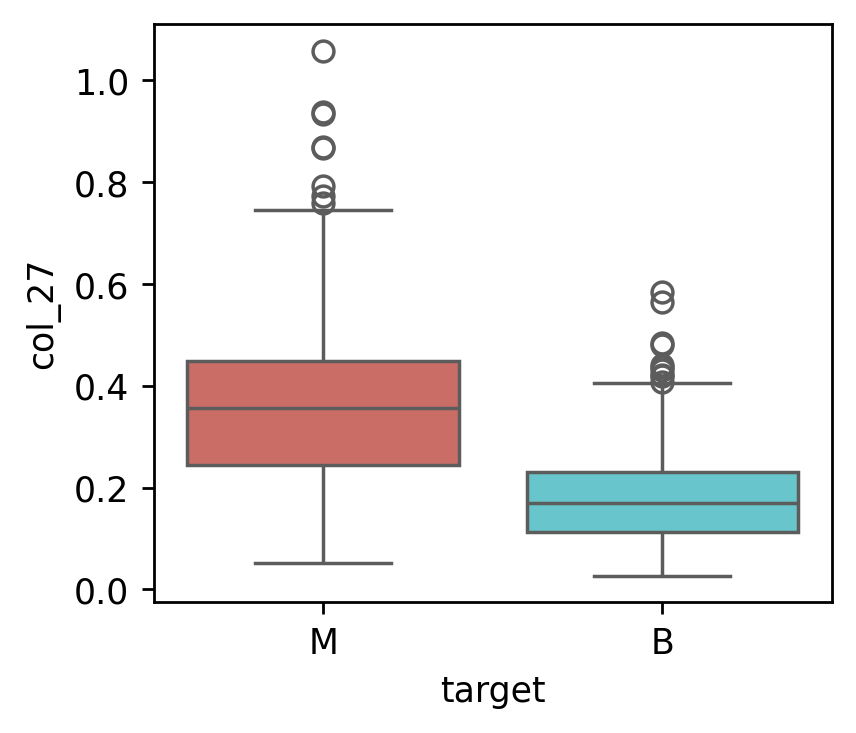

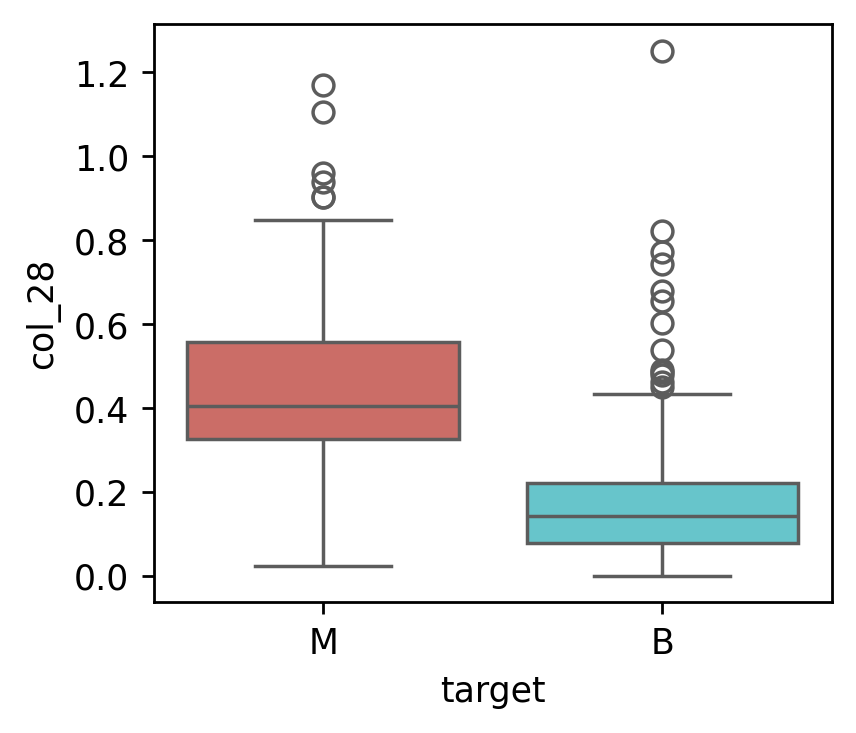

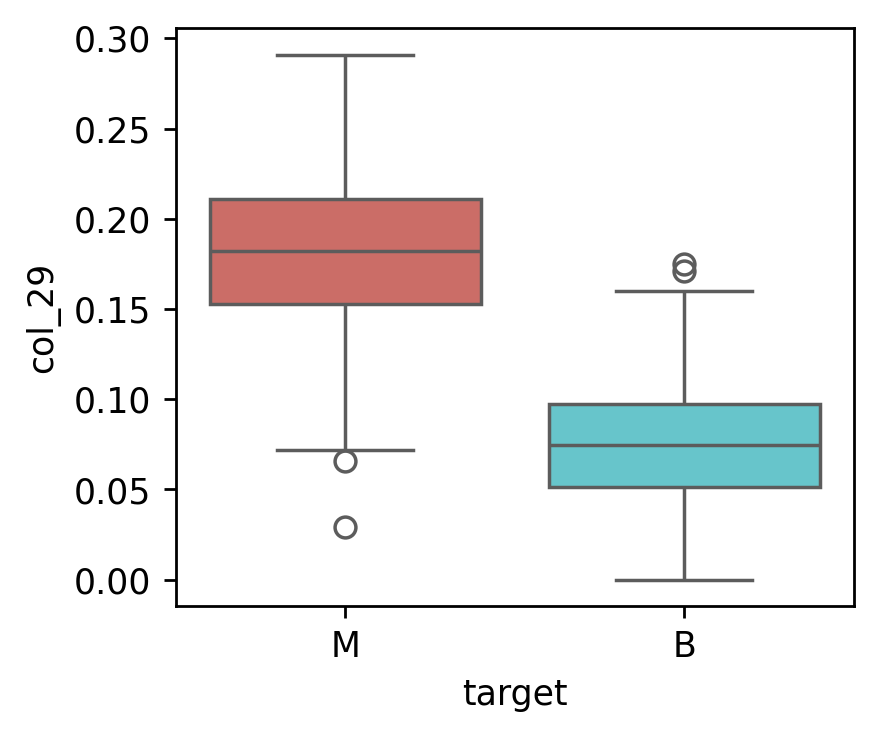

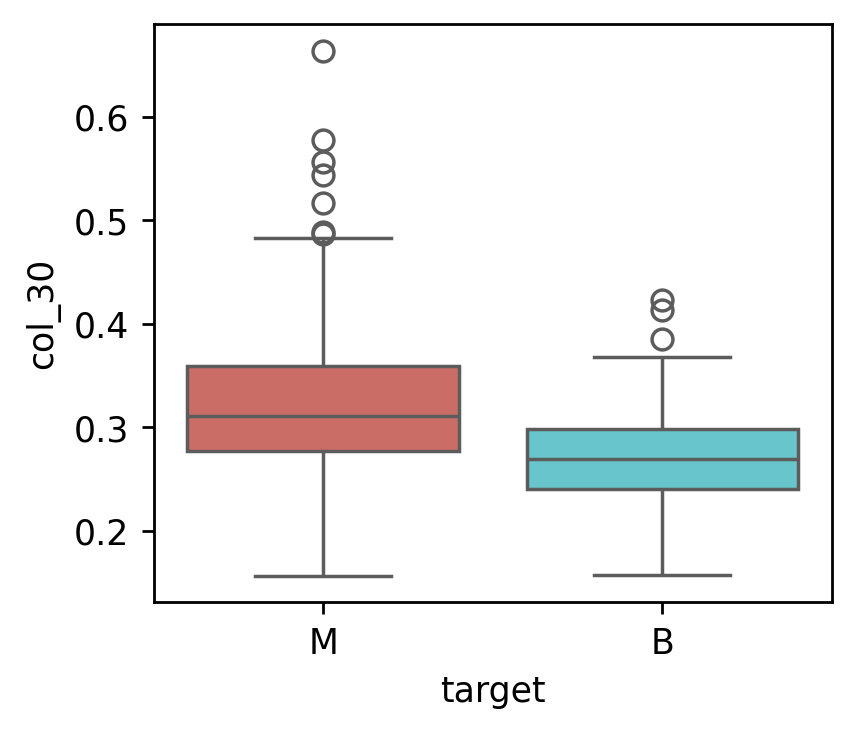

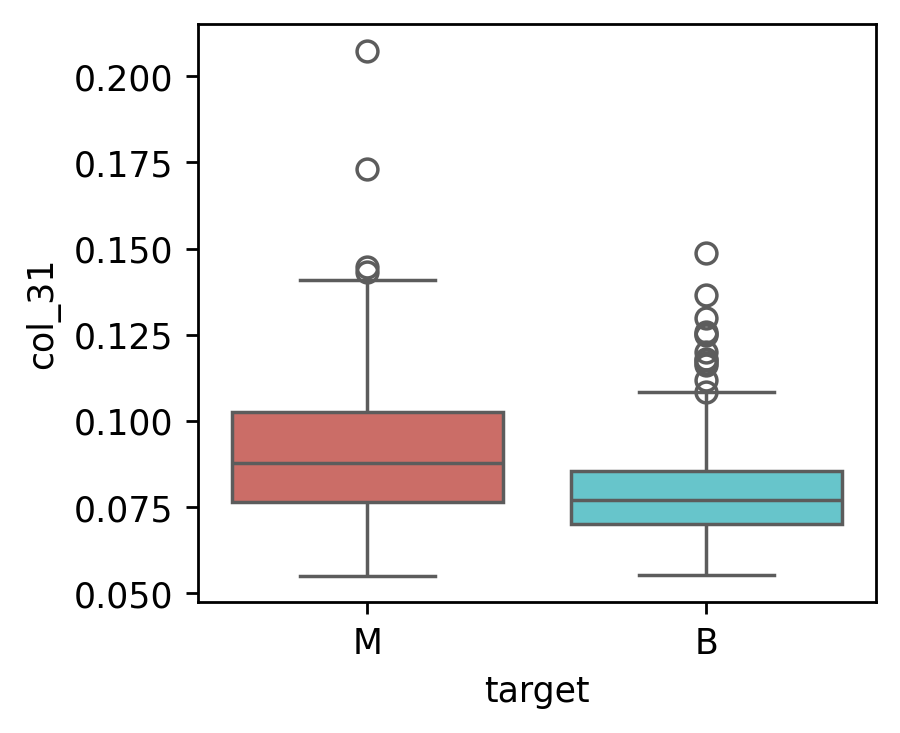

In [65]:
for col in df.drop("target", axis=1).columns:
    fig = plt.figure(figsize=(3.5, 3), dpi=250)
    sns.boxplot(data=df, y=col, palette="hls", x="target")
    plt.show()

In [68]:
df.to_csv("mlp_preproc_data.csv", sep=";")